# ViT Failure Diagnosis on Stanford Cars
**Explaining and interpreting the mistakes of a Vision Transformer**


| Step | What | Section |
|---|---|---|
| 1 | Load ViT, build labelled Stanford-Cars split (labels come from the devkit metadata) | 1-4 |
| 2-3 | Evaluate on held-out test split, build failure set **F** | 5 |
| 4 | Chefer / Gradient / Attention-Rollout maps, normalisation, agreement, top-K regions | 6-7 |
| 5 | Perturbation validation | 8 |
| 6 | Counterfactual analysis | 8 |
| 7-9 | Failure indicators, rule-based failure mode, stored diagnosis | 9-10 |
| 10-11 | Aggregation and comparisons (correct vs wrong, per class, per method) | 11 |
| 12 | Evaluation of the framework (deletion/insertion, localisation, faithfulness, human validation, consistency) | 12 |
| 13 | Final report | 13 |

**Design notes (read once)**
* Every image is **resized (squashed) to 224x224** with no crop, so the bounding box from the metadata maps exactly onto the model input and doubles as ground-truth object localisation.
* The ViT is fine-tuned from an ImageNet checkpoint (`timm`). Checkpoint is cached on Drive.


## 0. Setup

In [1]:
!pip install -q timm

In [2]:
import os, sys, math, json, time, pickle, shutil, random, warnings, glob
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import ndimage
from scipy.stats import spearmanr, mannwhitneyu

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF

import timm
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")
trapz = getattr(np, "trapezoid", None) or np.trapz
print("torch", torch.__version__, "| timm", timm.__version__)


class CFG:
    # ---------------- paths ----------------
    local_root = "/content/stanford_cars"                      # Kaggle download is extracted here (local disk, fast)
    out_dir    = "/content/drive/MyDrive/vit_diagnosis_outputs" # outputs/checkpoint on Drive so they persist

    # ---------------- model / data ----------------
    model_name = "vit_base_patch16_224.augreg_in21k_ft_in1k"
    img_size, patch = 224, 16
    grid = 14                                                   # img_size // patch
    val_frac, test_frac = 0.10, 0.20
    seed = 42

    # ---------------- fine-tuning ----------------
    epochs = 12
    batch_size = 64
    lr = 5e-5                                                   # backbone lr (head gets 10x)
    weight_decay = 0.05
    label_smoothing = 0.1
    num_workers = 2

    # ---------------- diagnosis ----------------
    n_correct_samples = 300      # correct predictions that get the same analysis (baseline for step 11)
    max_failures = None          # None = all failures; set e.g. 40 for a quick dry run
    attr_batch = 8               # images per attribution batch
    smoothgrad_n, smoothgrad_sigma = 10, 0.15
    topk_frac = 0.20             # "top" attribution = top 20% of patches
    region_k, region_w = 5, 3    # K candidate regions, each region_w x region_w patches (48x48 px)
    n_random_regions = 5         # random control regions per image
    perturb_mode = "mean"        # "mean" (dataset-mean grey) or "blur"
    n_refs = 3                   # reference images of y_true used for counterfactual region swap
    probe_bs = 128
    amp_probe = True             # fp16 autocast for the many perturbation forward passes

    # ---------------- evaluation (section 12) ----------------
    n_eval_failures = 300        # failures used for deletion/insertion + faithfulness (cap)
    n_eval_correct = 150
    delins_steps = 14
    human_per_mode = 10          # images per failure mode exported for manual labelling


FAILURE_MODES = ["BACKGROUND_RELIANCE", "LOCALIZATION_FAILURE", "TEXTURE_BIAS",
                 "CLASS_CONFUSION", "PARTIAL_OBJECT_FAILURE", "OTHER_AMBIGUOUS"]
METHODS = ["chefer", "grad", "rollout"]
ALL_MAPS = METHODS + ["consensus"]

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_cuda = device.type == "cuda"
print("device:", device, torch.cuda.get_device_name(0) if use_cuda else "(NO GPU - switch runtime to GPU!)")
S, P, G = CFG.img_size, CFG.patch, CFG.grid

torch 2.11.0+cu128 | timm 1.0.29
device: cuda Tesla T4


## 1. Data: download with the Kaggle CLI, locate files, read labels from the devkit metadata
Dataset: `eduardo4jesus/stanford-cars-dataset`.

In [3]:
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(CFG.out_dir, exist_ok=True)

Mounted at /content/drive


In [4]:
os.makedirs(CFG.local_root, exist_ok=True)
%cd {CFG.local_root}
if not glob.glob(f"{CFG.local_root}/**/cars_train_annos.mat", recursive=True):
    !kaggle datasets download eduardo4jesus/stanford-cars-dataset
    !unzip -q -o stanford-cars-dataset.zip
    !rm -f stanford-cars-dataset.zip
%cd /content

/content/stanford_cars
Dataset URL: https://www.kaggle.com/datasets/eduardo4jesus/stanford-cars-dataset
License(s): unknown
100% 1.82G/1.82G [00:18<00:00, 104MB/s] 

/content


In [5]:
# Locate the pieces wherever the archive put them
def find_one(pattern):
    hits = glob.glob(f"{CFG.local_root}/**/{pattern}", recursive=True)
    if not hits: raise FileNotFoundError(f"{pattern} not found under {CFG.local_root}; check the extracted folder layout")
    return hits[0]

devkit_dir = os.path.dirname(find_one("cars_train_annos.mat"))
# train image folder = folder holding 00001.jpg that is inside a path containing 'train'
img_dir = next(os.path.dirname(h) for h in glob.glob(f"{CFG.local_root}/**/00001.jpg", recursive=True) if "train" in h.lower())
print("devkit:", devkit_dir, "| images:", img_dir, "| n =", len(os.listdir(img_dir)))
assert len(os.listdir(img_dir)) == 8144, "expected 8,144 labelled training images"

devkit: /content/stanford_cars/car_devkit/devkit | images: /content/stanford_cars/cars_train/cars_train | n = 8144


In [6]:
def load_annos(path):
    a = sio.loadmat(path, squeeze_me=True, struct_as_record=False)["annotations"]
    return pd.DataFrame([dict(x1=int(r.bbox_x1), y1=int(r.bbox_y1), x2=int(r.bbox_x2), y2=int(r.bbox_y2),
                              label=int(getattr(r, "class")) - 1, fname=str(r.fname)) for r in a])

class_names = [str(c) for c in sio.loadmat(f"{devkit_dir}/cars_meta.mat", squeeze_me=True)["class_names"]]
df_all = load_annos(f"{devkit_dir}/cars_train_annos.mat")
df_all["image_id"] = df_all.fname.str.replace(".jpg", "", regex=False)
df_all["class_name"] = df_all.label.map(lambda i: class_names[i])
NUM_CLASSES = len(class_names)
print(len(df_all), "labelled images,", NUM_CLASSES, "classes")
df_all.head()

8144 labelled images, 196 classes


,x1,y1,x2,y2,label,fname,image_id,class_name
0,39,116,569,375,13,00001.jpg,00001,Audi TTS Coupe 2012
1,36,116,868,587,2,00002.jpg,00002,Acura TL Sedan 2012
2,85,109,601,381,90,00003.jpg,00003,Dodge Dakota Club Cab 2007
3,621,393,1484,1096,133,00004.jpg,00004,Hyundai Sonata Hybrid Sedan 2012
4,14,36,133,99,105,00005.jpg,00005,Ford F-450 Super Duty Crew Cab 2012


### Stratified train / val / test split (test = held-out portion of the labelled train data)

In [7]:
df_trval, df_test = train_test_split(df_all, test_size=CFG.test_frac, stratify=df_all.label, random_state=CFG.seed)
df_train, df_val = train_test_split(df_trval, test_size=CFG.val_frac / (1 - CFG.test_frac),
                                    stratify=df_trval.label, random_state=CFG.seed)
df_train, df_val, df_test = [d.reset_index(drop=True) for d in (df_train, df_val, df_test)]
print("train/val/test:", len(df_train), len(df_val), len(df_test))

train/val/test: 5700 815 1629


## 2. Dataset, transforms (bbox rescaled to the 224x224 input frame)

mean/std: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)


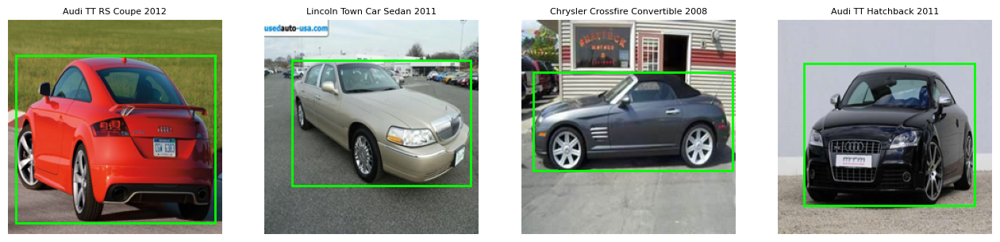

In [8]:
_tmp_model = timm.create_model(CFG.model_name, pretrained=False, num_classes=NUM_CLASSES)
data_cfg = timm.data.resolve_data_config({}, model=_tmp_model)
MEAN, STD = data_cfg["mean"], data_cfg["std"]
del _tmp_model
print("mean/std:", MEAN, STD)

tf_eval = T.Compose([T.Resize((S, S), interpolation=T.InterpolationMode.BICUBIC), T.ToTensor(), T.Normalize(MEAN, STD)])
tf_train = T.Compose([T.RandomResizedCrop(S, scale=(0.5, 1.0), interpolation=T.InterpolationMode.BICUBIC),
                      T.RandomHorizontalFlip(), T.ColorJitter(0.2, 0.2, 0.2),
                      T.ToTensor(), T.Normalize(MEAN, STD)])
_mean_t = torch.tensor(MEAN).view(3, 1, 1); _std_t = torch.tensor(STD).view(3, 1, 1)
def denorm(x):  # normalised tensor (3,H,W) -> [0,1] image
    return (x.cpu() * _std_t + _mean_t).clamp(0, 1)


class CarsDS(Dataset):
    """Returns (image, label, index, bbox[x1,y1,x2,y2] in 224-pixel coordinates)."""
    def __init__(self, df, img_dir, train=False):
        self.df, self.img_dir, self.tf = df.reset_index(drop=True), img_dir, (tf_train if train else tf_eval)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(f"{self.img_dir}/{r.fname}").convert("RGB")
        W, H = img.size
        bbox = np.array([r.x1 / W * S, r.y1 / H * S, r.x2 / W * S, r.y2 / H * S], dtype=np.float32)
        return self.tf(img), int(r.label), i, bbox

ds_train = CarsDS(df_train, img_dir, train=True)
ds_train_eval = CarsDS(df_train, img_dir, train=False)     # same images, deterministic transform
ds_val  = CarsDS(df_val, img_dir)
ds_test = CarsDS(df_test, img_dir)
mk = lambda ds, shuffle: DataLoader(ds, batch_size=CFG.batch_size, shuffle=shuffle, num_workers=CFG.num_workers,
                                    pin_memory=use_cuda, drop_last=shuffle, persistent_workers=CFG.num_workers > 0)
dl_train, dl_val, dl_test, dl_train_eval = mk(ds_train, True), mk(ds_val, False), mk(ds_test, False), mk(ds_train_eval, False)

# quick visual check that bbox and label are aligned
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, i in zip(axs, np.random.RandomState(0).choice(len(ds_test), 4, replace=False)):
    x, y, _, b = ds_test[i]
    ax.imshow(denorm(x).permute(1, 2, 0)); ax.add_patch(mpatches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="lime", lw=2))
    ax.set_title(class_names[y], fontsize=8); ax.axis("off")
plt.show()

## 3. Model: ViT-B/16, fine-tuned on the Cars train split (step 1)

In [9]:
model = timm.create_model(CFG.model_name, pretrained=True, num_classes=NUM_CLASSES).to(device)
ckpt_path = f"{CFG.out_dir}/vit_cars_best.pt"

@torch.no_grad()
def predict_loader(model, dl):
    """Returns logits (N,C) and pre-logit CLS features (N,D), in dataset order."""
    model.eval(); L, Fe = [], []
    for x, *_ in tqdm(dl, leave=False):
        x = x.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda):
            f = model.forward_head(model.forward_features(x), pre_logits=True)
            l = model.head(f)
        L.append(l.float().cpu()); Fe.append(f.float().cpu())
    return torch.cat(L).numpy(), torch.cat(Fe).numpy()

def train_model(model):
    head = [p for n, p in model.named_parameters() if n.startswith("head")]
    base = [p for n, p in model.named_parameters() if not n.startswith("head")]
    opt = torch.optim.AdamW([{"params": base, "lr": CFG.lr}, {"params": head, "lr": CFG.lr * 10}], weight_decay=CFG.weight_decay)
    total, warm = CFG.epochs * len(dl_train), len(dl_train)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
    crit = nn.CrossEntropyLoss(label_smoothing=CFG.label_smoothing)
    best = 0.0
    for ep in range(CFG.epochs):
        model.train(); run, n = 0.0, 0
        for x, y, *_ in tqdm(dl_train, desc=f"epoch {ep+1}/{CFG.epochs}", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda):
                loss = crit(model(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * len(y); n += len(y)
        lv, _ = predict_loader(model, dl_val)
        acc = (lv.argmax(1) == df_val.label.values).mean()
        print(f"epoch {ep+1:2d} | train loss {run/n:.3f} | val acc {acc:.4f}")
        if acc > best:
            best = acc; torch.save(model.state_dict(), ckpt_path)
    print("best val acc", best)

if os.path.exists(ckpt_path):
    model.load_state_dict(torch.load(ckpt_path, map_location=device)); print("loaded checkpoint", ckpt_path)
else:
    train_model(model)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval();

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/12:   0%|          | 0/89 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

epoch  1 | train loss 4.820 | val acc 0.3374


...

  0%|          | 0/13 [00:00<?, ?it/s]

epoch 11 | train loss 0.935 | val acc 0.8650


epoch 12/12:   0%|          | 0/89 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

epoch 12 | train loss 0.927 | val acc 0.8699
best val acc 0.8699386503067484


## 4. Evaluate on the test split and build the failure set F (steps 2 and 3)
For every image: `y_true`, `y_pred = argmax f(x)`, `p_pred`. Wrong predictions go into **F**.

In [10]:
logits_test, feats_test = predict_loader(model, dl_test)
probs_test = torch.softmax(torch.from_numpy(logits_test), 1).numpy()
order = np.argsort(-probs_test, 1)

res = df_test.copy()
res["y_true"] = res.label.values
res["y_pred"] = probs_test.argmax(1)                              # 3.1  y_pred = argmax f(x)
res["p_pred"] = probs_test.max(1)                                 #      p_pred = confidence of y_pred
res["p_true"] = probs_test[np.arange(len(res)), res.y_true.values]
res["p_second"] = probs_test[np.arange(len(res)), order[:, 1]]
res["second"] = order[:, 1]
res["margin"] = res.p_pred - res.p_second                         # PredictionMargin (top1 - top2 prob)
res["correct"] = res.y_pred == res.y_true                         # 3.2 / 3.3

F_set = res[~res.correct]                                          # Failure set F
C_set = res[res.correct]
print(f"test acc = {res.correct.mean():.4f}  |  correct = {len(C_set)}  |  |F| = {len(F_set)}")
print("top-5 acc =", np.mean([res.y_true[i] in order[i, :5] for i in range(len(res))]).round(4))
print(f"mean confidence  correct: {C_set.p_pred.mean():.3f}   wrong: {F_set.p_pred.mean():.3f}")
res.to_csv(f"{CFG.out_dir}/test_predictions.csv", index=False)
F_set.head()

  0%|          | 0/26 [00:00<?, ?it/s]

test acc = 0.8643  |  correct = 1408  |  |F| = 221
top-5 acc = 0.9736
mean confidence  correct: 0.572   wrong: 0.247


,x1,y1,x2,y2,label,fname,image_id,class_name,y_true,y_pred,p_pred,p_true,p_second,second,margin,correct
11,147,517,1942,1269,19,03887.jpg,03887,Audi S6 Sedan 2011,19,25,0.172632,0.024628,0.084629,22,0.088004,False
15,135,86,463,300,176,02045.jpg,02045,Rolls-Royce Phantom Sedan 2012,176,175,0.854826,0.002985,0.006204,36,0.848622,False
19,2,24,255,138,73,06848.jpg,06848,Chevrolet Silverado 1500 Extended Cab 2012,73,53,0.465189,0.269231,0.269231,73,0.195958,False
21,22,71,280,166,170,07970.jpg,07970,Nissan 240SX Coupe 1998,170,16,0.259788,0.086004,0.086004,170,0.173784,False
32,2,57,625,391,73,02859.jpg,02859,Chevrolet Silverado 1500 Extended Cab 2012,73,53,0.285882,0.277086,0.277086,73,0.008796,False


### Class prototypes (used later for RepresentationSimilarity)

In [11]:
logits_tr, feats_tr = predict_loader(model, dl_train_eval)
def l2n(a): return a / (np.linalg.norm(a, axis=-1, keepdims=True) + 1e-12)
protos = l2n(np.stack([feats_tr[df_train.label.values == c].mean(0) for c in range(NUM_CLASSES)]))   # (C,D)
proto_cos = protos @ protos.T                                                                         # (C,C)
np.fill_diagonal(proto_cos, -1)
proto_rank = (-proto_cos).argsort(1).argsort(1) + 1       # proto_rank[a,b] = rank of b among neighbours of a (1 = nearest)
base_name = lambda n: n.rsplit(" ", 1)[0]                  # drop the model year: "Audi S4 Sedan 2007" -> "Audi S4 Sedan"
make_of = lambda n: n.split(" ")[0]
print("nearest classes of", class_names[0], "->", [class_names[j] for j in (-proto_cos[0]).argsort()[:4]])

  0%|          | 0/90 [00:00<?, ?it/s]

nearest classes of AM General Hummer SUV 2000 -> ['HUMMER H2 SUT Crew Cab 2009', 'Jeep Wrangler SUV 2012', 'HUMMER H3T Crew Cab 2010', 'Jeep Patriot SUV 2012']


## 5. Attribution methods (step 4.1)
* **Chefer** - Generic Attention Model Explainability: for each block `A_bar = E_h[(grad_A * A)^+]`, `R <- R + A_bar @ R`; the CLS row gives patch relevance for the explained class.
* **Gradient** - SmoothGrad of the input gradient of the class logit (channel-max of |grad|, lightly blurred).
* **Attention Rollout** - Abnar & Zuidema: product of head-averaged attention with residual identity. Class-agnostic by construction (as in the algorithm: `AttentionRollout(f, x)`).

Attention is captured by swapping each block's `attn_drop` for a recording module (works with recent `timm`). Fused/flash attention is switched off only while attention maps are needed.

In [12]:
class AttnHook(nn.Module):
    """Wraps attn_drop: records the post-softmax attention tensor (B,H,N,N) of one block."""
    def __init__(self, inner):
        super().__init__(); self.inner, self.attn = inner, None
    def forward(self, a):
        self.attn = a
        return self.inner(a)


class ViTExplainer:
    def __init__(self, model):
        self.model = model.eval()
        assert getattr(model, "num_prefix_tokens", 1) == 1, "expects a plain ViT with one CLS token"
        self.hooks = []
        for blk in model.blocks:
            h = AttnHook(blk.attn.attn_drop); blk.attn.attn_drop = h; self.hooks.append(h)

    def set_fused(self, flag):
        for blk in self.model.blocks:
            if hasattr(blk.attn, "fused_attn"): blk.attn.fused_attn = flag

    def _check(self):
        if any(h.attn is None for h in self.hooks):
            raise RuntimeError("attention was not captured; your timm version bypasses attn_drop (try `pip install -U timm`).")

    @torch.no_grad()
    def probs(self, x):
        self.set_fused(True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_cuda and CFG.amp_probe):
            out = self.model(x)
        return torch.softmax(out.float(), -1)

    def chefer(self, x, target):
        self.set_fused(False)
        with torch.enable_grad():
            logits = self.model(x)
            self._check()
            score = (logits * F.one_hot(target, logits.shape[-1]).float()).sum()
            grads = torch.autograd.grad(score, [h.attn for h in self.hooks])
        B, N = x.shape[0], self.hooks[0].attn.shape[-1]
        R = torch.eye(N, device=x.device).unsqueeze(0).repeat(B, 1, 1)
        for h, g in zip(self.hooks, grads):
            Abar = (g * h.attn.detach()).clamp(min=0).mean(1)       # (B,N,N)  positive grad-weighted attention
            R = R + torch.bmm(Abar, R)
        return R[:, 0, 1:].reshape(B, G, G).detach()

    @torch.no_grad()
    def rollout(self, x):
        self.set_fused(False)
        self.model(x); self._check()
        B, N = x.shape[0], self.hooks[0].attn.shape[-1]
        I = torch.eye(N, device=x.device)
        R = I.unsqueeze(0).repeat(B, 1, 1)
        for h in self.hooks:
            A = 0.5 * h.attn.mean(1) + 0.5 * I
            A = A / A.sum(-1, keepdim=True)
            R = torch.bmm(A, R)
        return R[:, 0, 1:].reshape(B, G, G)

    def gradient(self, x, target, n=None, sigma=None):
        n, sigma = n or CFG.smoothgrad_n, sigma or CFG.smoothgrad_sigma
        self.set_fused(True)
        rng_ = (x.amax((1, 2, 3), keepdim=True) - x.amin((1, 2, 3), keepdim=True))
        acc = torch.zeros(x.shape[0], S, S, device=x.device)
        oh = F.one_hot(target, NUM_CLASSES).float()
        for _ in range(n):
            xn = (x + torch.randn_like(x) * sigma * rng_).requires_grad_(True)
            with torch.enable_grad():
                score = (self.model(xn) * oh).sum()
                g, = torch.autograd.grad(score, xn)
            acc += g.abs().amax(1)
        acc = TF.gaussian_blur((acc / n).unsqueeze(1), kernel_size=15, sigma=4.0).squeeze(1)
        return acc.detach()

    def all_maps(self, x, target):
        """Returns dict name -> (B,224,224) maps in [0,1], all at the same resolution (step 4.2)."""
        raw = {"chefer": self.chefer(x, target), "grad": self.gradient(x, target), "rollout": self.rollout(x)}
        return {k: normalize_map(v) for k, v in raw.items()}


def normalize_map(m):
    """(B,h,w) -> (B,224,224), bilinear upsample (if needed) + per-image min-max to [0,1]."""
    m = m.float()
    if m.shape[-1] != S:
        m = F.interpolate(m.unsqueeze(1), size=(S, S), mode="bilinear", align_corners=False).squeeze(1)
    mn, mx = m.amin((1, 2), keepdim=True), m.amax((1, 2), keepdim=True)
    return (m - mn) / (mx - mn + 1e-12)

explainer = ViTExplainer(model)

### Sanity check on one failure: the three maps should look sensible and Chefer/Rollout should highlight the car

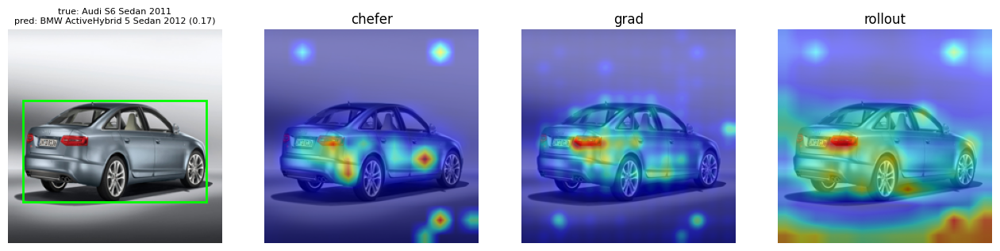

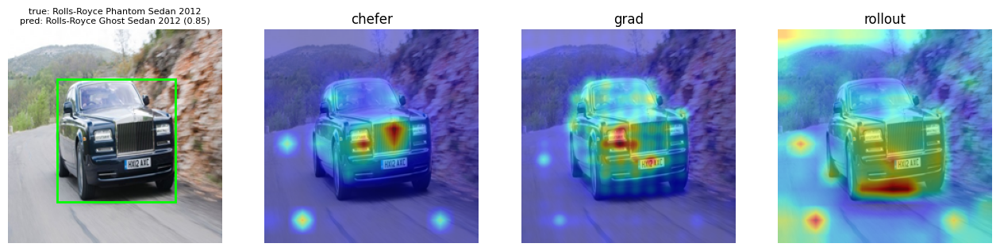

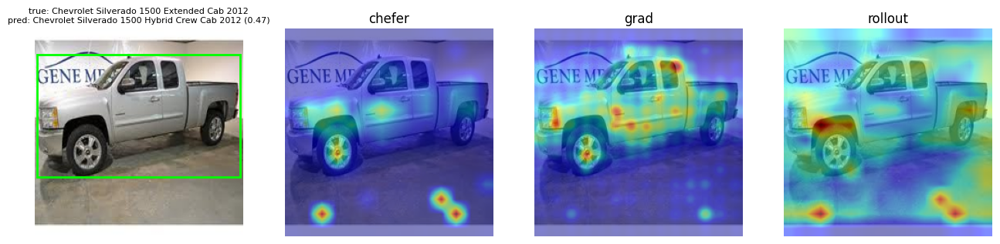

In [13]:
def get_item(ds, i):
    x, y, _, b = ds[i]
    return x, y, b

def show_maps(i, ds=ds_test, df=res):
    x, y, b = get_item(ds, i)
    yp = int(df.y_pred.iloc[i])
    m = explainer.all_maps(x[None].to(device), torch.tensor([yp], device=device))
    fig, axs = plt.subplots(1, 4, figsize=(16, 4.3))
    img = denorm(x).permute(1, 2, 0)
    axs[0].imshow(img); axs[0].add_patch(mpatches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="lime", lw=2))
    axs[0].set_title(f"true: {class_names[y]}\npred: {class_names[yp]} ({df.p_pred.iloc[i]:.2f})", fontsize=8)
    for ax, k in zip(axs[1:], METHODS):
        ax.imshow(img); ax.imshow(m[k][0].cpu(), cmap="jet", alpha=0.5); ax.set_title(k)
    for ax in axs: ax.axis("off")
    plt.show()

for i in F_set.index[:3]:
    show_maps(i)

## 6. Geometry helpers: object mask, regions, agreement, indicators (steps 4.2-4.4)

In [14]:
def pool14(m224):                      # (224,224) -> (14,14) patch-level mean
    return m224.reshape(G, P, G, P).mean((1, 3))

def up224(m14):                        # (14,14) -> (224,224), nearest (patch aligned)
    return np.kron(m14, np.ones((P, P), dtype=m14.dtype))

def bbox_mask(b):
    x1, y1 = int(np.clip(np.floor(b[0]), 0, S)), int(np.clip(np.floor(b[1]), 0, S))
    x2, y2 = int(np.clip(np.ceil(b[2]), 0, S)), int(np.clip(np.ceil(b[3]), 0, S))
    m = np.zeros((S, S), np.float32); m[y1:y2, x1:x2] = 1
    return m

def truncated_sides(b, margin=0.02):
    """How many image borders the car box touches (cropped car => part of the object is missing)."""
    t = margin * S
    return int(b[0] <= t) + int(b[1] <= t) + int(b[2] >= S - t) + int(b[3] >= S - t)

def texture14(img01):
    """Local texture energy per patch: mean Sobel gradient magnitude of the grey image. -> (14,14)"""
    g = (0.299 * img01[0] + 0.587 * img01[1] + 0.114 * img01[2])[None, None]
    kx = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]])[None, None]
    gx, gy = F.conv2d(g, kx, padding=1), F.conv2d(g, kx.transpose(2, 3), padding=1)
    return pool14((gx ** 2 + gy ** 2).sqrt()[0, 0].numpy())

def topk_mask(a14, frac=None):
    frac = frac or CFG.topk_frac
    k = max(1, int(round(frac * a14.size)))
    thr = np.sort(a14.ravel())[-k]
    return a14 >= thr

def top_regions(a14, K=None, w=None):
    """Greedy non-overlapping w x w patch windows with highest attribution mass (step 4.4)."""
    K, w = K or CFG.region_k, w or CFG.region_w
    a, out = a14.copy(), []
    for _ in range(K):
        ws = ndimage.uniform_filter(a, size=w, mode="constant")
        i, j = np.unravel_index(np.argmax(ws), ws.shape)
        r0, c0 = int(np.clip(i - w // 2, 0, G - w)), int(np.clip(j - w // 2, 0, G - w))
        out.append((r0, c0))
        a[r0:r0 + w, c0:c0 + w] = -1e3
    return out

def region_mask(r0, c0, w=None):
    w = w or CFG.region_w
    m = np.zeros((S, S), np.float32); m[r0 * P:(r0 + w) * P, c0 * P:(c0 + w) * P] = 1
    return m

def agreement(a14s):
    """Step 4.3: pairwise Spearman rank correlation and top-k IoU between the three methods."""
    names, sp, iou = list(a14s), {}, {}
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            u, v = a14s[names[i]], a14s[names[j]]
            r = spearmanr(u.ravel(), v.ravel()).correlation
            tu, tv = topk_mask(u), topk_mask(v)
            key = f"{names[i]}-{names[j]}"
            sp[key] = float(0 if np.isnan(r) else r); iou[key] = float((tu & tv).sum() / (tu | tv).sum())
    return dict(spearman_pairs=sp, iou_pairs=iou, spearman=float(np.mean(list(sp.values()))), iou=float(np.mean(list(iou.values()))))

def map_indicators(a14, m14, tex14):
    """Indicators of ONE attribution map, relative to the object box (m14 = box coverage per patch)."""
    a = a14 / (a14.sum() + 1e-12)
    obj_mass = float((a * m14).sum()); obj_area = float(m14.mean())
    ent = -(a * np.log(a + 1e-12)).sum()
    top, obj_bin = topk_mask(a), m14 >= 0.5
    return dict(
        obj_mass=obj_mass, bg_mass=1 - obj_mass,
        obj_ratio=obj_mass / (obj_area + 1e-6),                       # >1: attribution enriched on the object
        bg_ratio=(1 - obj_mass) / (1 - obj_area + 1e-6),              # >1: enriched on the background
        concentration=float(1 - ent / np.log(a.size)),                # 0 = uniform, 1 = single patch
        top10_share=float(np.sort(a.ravel())[-max(1, a.size // 10):].sum()),
        pointing_hit=bool(obj_bin.ravel()[np.argmax(a)]),             # does the peak fall inside the box?
        topk_in_obj=float((top & obj_bin).sum() / max(1, top.sum())), # share of top-k patches inside the box
        iou_topk_box=float((top & obj_bin).sum() / max(1, (top | obj_bin).sum())),
        obj_coverage=float(((a >= a.mean()) & obj_bin).sum() / max(1, obj_bin.sum())),  # object patches that get >= uniform attention
        texture_ratio=float((a * tex14).sum() / (tex14.mean() + 1e-12)),                 # >1: attribution sits on high-texture patches
    )

## 7. Perturbation + counterfactual machinery (steps 5 and 6)
* `Perturb(x, r)`: the region's pixels are replaced by a baseline (`mean` grey or a heavy `blur` of the same image).
* Controls per image: **object box removed**, **background removed**, **patch-shuffled image** (destroys shape, keeps local texture), **random regions** of the same size.
* Counterfactual on the most influential regions `R*` (largest `Delta`): (i) *remove* them, (ii) *swap* them with the same location of a reference image of the **true class**.

In [15]:
def make_baseline(x, mode=None):
    mode = mode or CFG.perturb_mode
    if mode == "mean": return torch.zeros_like(x)                       # = dataset mean after normalisation
    return TF.gaussian_blur(x.unsqueeze(0), kernel_size=51, sigma=15.0)[0]

def fill(x, base, mask):
    m = torch.as_tensor(mask, device=x.device, dtype=x.dtype)
    return x * (1 - m) + base * m

def patch_shuffle(x, gen):
    p = x.unfold(1, P, P).unfold(2, P, P).reshape(3, G * G, P, P)        # (3,196,16,16)
    p = p[:, torch.randperm(G * G, generator=gen).to(x.device)]
    return p.reshape(3, G, G, P, P).permute(0, 1, 3, 2, 4).reshape(3, S, S)

@torch.no_grad()
def probe(xs, y_pred, y_true):
    """Forward a stack of images; return p(y_pred), p(y_true), argmax and max prob for each."""
    pp, pt, am, pm = [], [], [], []
    for i in range(0, len(xs), CFG.probe_bs):
        pr = explainer.probs(xs[i:i + CFG.probe_bs]).cpu()
        pp.append(pr[:, y_pred]); pt.append(pr[:, y_true]); am.append(pr.argmax(1)); pm.append(pr.max(1).values)
    return dict(p_pred=torch.cat(pp).numpy(), p_true=torch.cat(pt).numpy(), pred=torch.cat(am).numpy(), p_max=torch.cat(pm).numpy())

_ref_cache = {}
def get_refs(cls, exclude_idx=None):
    """n_refs deterministic train images of class `cls` (normalised tensors) for the region-swap counterfactual."""
    if cls not in _ref_cache:
        idx = np.where(df_train.label.values == cls)[0]
        idx = np.random.RandomState(cls).permutation(idx)[:CFG.n_refs]
        _ref_cache[cls] = torch.stack([ds_train_eval[int(i)][0] for i in idx])
    return _ref_cache[cls]

GRID_CELL = 2                       # faithfulness grid: 7x7 cells of 2x2 patches
N_CELLS = (G // GRID_CELL) ** 2
def cell_mask(ci):
    n = G // GRID_CELL; r, c = divmod(ci, n); m = np.zeros((S, S), np.float32)
    m[r*GRID_CELL*P:(r+1)*GRID_CELL*P, c*GRID_CELL*P:(c+1)*GRID_CELL*P] = 1
    return m

def cell_sums(a14):
    n = G // GRID_CELL
    return a14.reshape(n, GRID_CELL, n, GRID_CELL).sum((1, 3)).ravel()

## 8. Diagnose one batch of images (steps 4-7)
For each image this produces: attribution maps -> agreement -> candidate regions -> perturbation scores -> counterfactuals -> indicators.

In [16]:
maps_store = {}        # image_id -> float16 array (4, 224, 224): chefer, grad, rollout, consensus
records = []           # step 9: one diagnosis dict per analysed image


def rep_similarity(feat, y_pred, alt):
    """alt = true class for a failure, runner-up class for a correct prediction."""
    f = l2n(feat)
    return dict(cos_to_alt_proto=float(f @ protos[alt]), cos_to_pred_proto=float(f @ protos[y_pred]),
                proto_cos_pred_alt=float(proto_cos[y_pred, alt]), nbr_rank=int(proto_rank[y_pred, alt]),
                same_make=make_of(class_names[y_pred]) == make_of(class_names[alt]),
                same_model_other_year=base_name(class_names[y_pred]) == base_name(class_names[alt]))


def diagnose_batch(idxs, group, rng):
    B = len(idxs)
    items = [ds_test[int(i)] for i in idxs]
    xs = torch.stack([it[0] for it in items]).to(device)
    ytrue = np.array([it[1] for it in items]); bboxes = np.stack([it[3] for it in items])
    ypred = res.y_pred.values[idxs]
    tgt = torch.tensor(ypred, device=device)

    # ---- 4.1 attribution maps (+ 4.2 same resolution) ----
    maps = explainer.all_maps(xs, tgt)
    maps = {k: v.cpu().numpy() for k, v in maps.items()}

    for b in range(B):
        i, yp, yt, bbox = int(idxs[b]), int(ypred[b]), int(ytrue[b]), bboxes[b]
        x = xs[b]; base = make_baseline(x)
        correct = yp == yt
        alt = yt if not correct else int(res.second.values[i])              # class we compare against
        row = res.iloc[i]
        img01 = denorm(x)

        a14 = {k: pool14(maps[k][b]) for k in METHODS}
        a14n = {k: v / (v.sum() + 1e-12) for k, v in a14.items()}            # each method -> unit mass
        a14["consensus"] = np.mean([a14n[k] for k in METHODS], 0)            # equal-weight mass consensus
        maps224 = {k: maps[k][b] for k in METHODS}
        # consensus at the common 224x224 resolution (bilinear, smooth)
        maps224["consensus"] = normalize_map(torch.from_numpy(a14["consensus"])[None].float())[0].numpy()
        maps_store[row.image_id] = np.stack([maps224[k] for k in ALL_MAPS]).astype(np.float16)

        # ---- 4.3 agreement ----
        agr = agreement({k: a14[k] for k in METHODS})

        # ---- 4.4 candidate regions R = TopKRegions(...) ----
        m_box = bbox_mask(bbox); m14 = pool14(m_box); tex14 = texture14(img01)
        regs = top_regions(a14["consensus"])
        w = CFG.region_w
        regions = []
        for (r0, c0) in regs:
            sl = (slice(r0, r0 + w), slice(c0, c0 + w))
            regions.append(dict(r0=r0, c0=c0, size=w, mass=float(a14["consensus"][sl].sum() / a14["consensus"].sum()),
                                in_object=float(m14[sl].mean()),
                                support={k: float(topk_mask(a14[k])[sl].mean()) for k in METHODS}))   # share of window inside each method's top-k
        rand_regs = [(int(rng.integers(0, G - w + 1)), int(rng.integers(0, G - w + 1))) for _ in range(CFG.n_random_regions)]

        # ---- 5. perturbation batch (single forward) ----
        gen = torch.Generator().manual_seed(int(rng.integers(1 << 30)))
        stack, tag = [x], ["orig"]
        stack.append(fill(x, base, m_box)); tag.append("obj")
        stack.append(fill(x, base, 1 - m_box)); tag.append("bg")
        for _ in range(2): stack.append(patch_shuffle(x, gen)); tag.append("shuf")
        for (r0, c0) in regs: stack.append(fill(x, base, region_mask(r0, c0))); tag.append("reg")
        for (r0, c0) in rand_regs: stack.append(fill(x, base, region_mask(r0, c0))); tag.append("rnd")
        for ci in range(N_CELLS): stack.append(fill(x, base, cell_mask(ci))); tag.append("cell")
        pr = probe(torch.stack(stack), yp, yt)
        tag = np.array(tag); sel = lambda t: np.where(tag == t)[0]
        p0 = float(pr["p_pred"][0]); p0_true = float(pr["p_true"][0])
        drop = lambda ids: p0 - pr["p_pred"][ids]                            # Delta = p_original - p_perturbed
        reg_drop, rnd_drop, cell_drop = drop(sel("reg")), drop(sel("rnd")), drop(sel("cell"))
        for r, d, pe in zip(regions, reg_drop, pr["p_pred"][sel("reg")]):
            r["delta"] = float(d); r["p_perturbed"] = float(pe)
        pert = dict(
            p_original=p0, region_delta=reg_drop.tolist(), region_flip=(pr["pred"][sel("reg")] != yp).tolist(),
            random_delta=rnd_drop.tolist(), cell_delta=cell_drop.tolist(),
            obj_removed_delta=float(drop(sel("obj"))[0]), bg_removed_delta=float(drop(sel("bg"))[0]),
            obj_removed_flip=bool(pr["pred"][1] != yp), bg_removed_flip=bool(pr["pred"][2] != yp),
            shuffle_keep=float(pr["p_pred"][sel("shuf")].mean() / max(p0, 1e-6)),
            max_region_delta=float(reg_drop.max()), mean_region_delta=float(reg_drop.mean()),
            mean_random_delta=float(rnd_drop.mean()))

        # ---- 6. counterfactual analysis on R* (regions with the largest Delta) ----
        star = np.argsort(-reg_drop)[:2]
        m_star = np.clip(sum(region_mask(regs[s][0], regs[s][1]) for s in star), 0, 1)
        cf_stack, cf_tag = [fill(x, base, m_star)], ["remove"]
        if not correct:
            refs = get_refs(yt).to(device)
            for r_ in refs: cf_stack.append(fill(x, r_, m_star)); cf_tag.append("swap")
        pc = probe(torch.stack(cf_stack), yp, yt)
        def cf_entry(j):
            return dict(p_pred_cf=float(pc["p_pred"][j]), p_true_cf=float(pc["p_true"][j]), pred_cf=int(pc["pred"][j]),
                        reduces_conf_pred=bool(pc["p_pred"][j] < p0), increases_conf_true=bool(pc["p_true"][j] > p0_true),
                        changes_class=bool(pc["pred"][j] != yp), flips_to_true=bool(pc["pred"][j] == yt) and not correct,
                        delta_pred=float(p0 - pc["p_pred"][j]), delta_true=float(pc["p_true"][j] - p0_true))
        cf = dict(R_star=[dict(r0=regs[s][0], c0=regs[s][1]) for s in star], remove=cf_entry(0))
        if not correct:
            j = 1 + int(np.argmax(pc["p_true"][1:]))                           # strongest of the reference swaps
            cf["swap_true_class"] = cf_entry(j)

        # ---- 7. failure indicators ----
        mi = {k: map_indicators(a14[k], m14, tex14) for k in ALL_MAPS}
        rep = rep_similarity(feats_test[i], yp, alt)
        cons = mi["consensus"]
        cf_best = cf["swap_true_class"] if not correct else cf["remove"]
        indicators = dict(
            BackgroundReliance=cons["bg_mass"],
            ObjectReliance=cons["obj_mass"],
            AttributionConcentration=cons["concentration"],
            AttributionAgreement=agr["spearman"],
            PerturbationImpact=pert["max_region_delta"],
            PredictionMargin=float(row.margin),
            CounterfactualEffect=max(cf["remove"]["delta_pred"], cf_best["delta_pred"], cf_best["delta_true"]),
            RepresentationSimilarity=rep["proto_cos_pred_alt"])
        aux = dict(bg_rel_drop=pert["bg_removed_delta"] / max(p0, 1e-6), bg_flip=pert["bg_removed_flip"],
                   obj_rel_drop=pert["obj_removed_delta"] / max(p0, 1e-6), obj_flip=pert["obj_removed_flip"],
                   shuffle_keep=pert["shuffle_keep"], trunc_sides=truncated_sides(bbox),
                   box_area=float(m14.mean()), alt_class=alt, **{f"rep_{k}": v for k, v in rep.items()})
        records.append(dict(
            image_id=row.image_id, idx=i, group=group, y_true=yt, y_pred=yp,
            true_class=class_names[yt], predicted_class=class_names[yp], confidence=float(row.p_pred), p_true=float(row.p_true),
            bbox=bbox.tolist(), attribution_maps=row.image_id,                 # key into maps_store
            important_regions=regions, perturbation_scores=pert, counterfactual_results=cf,
            agreement=agr, map_indicators=mi, failure_indicators=indicators, aux=aux, failure_mode=None))


def run_diagnosis(idx_list, group, seed):
    rng = np.random.default_rng(seed)
    idx_list = np.asarray(idx_list)
    for s in tqdm(range(0, len(idx_list), CFG.attr_batch), desc=f"diagnosing {group}"):
        diagnose_batch(idx_list[s:s + CFG.attr_batch], group, rng)

In [17]:
fail_idx = F_set.index.values
if CFG.max_failures: fail_idx = fail_idx[:CFG.max_failures]
corr_idx = np.random.RandomState(CFG.seed).choice(C_set.index.values, min(CFG.n_correct_samples, len(C_set)), replace=False)

records.clear(); maps_store.clear()
t0 = time.time()
run_diagnosis(fail_idx, "failure", CFG.seed)
run_diagnosis(corr_idx, "correct", CFG.seed + 1)
print(f"{len(records)} images diagnosed in {(time.time()-t0)/60:.1f} min")

# cache so a Colab disconnect doesn't cost the whole run
with open(f"{CFG.out_dir}/records_raw.pkl", "wb") as f: pickle.dump(records, f)
np.savez_compressed(f"{CFG.out_dir}/attribution_maps.npz", **maps_store)

diagnosing failure:   0%|          | 0/28 [00:00<?, ?it/s]

diagnosing correct:   0%|          | 0/38 [00:00<?, ?it/s]

521 images diagnosed in 4.4 min


## 9. Failure-mode rules (step 8)
Rule order follows the algorithm exactly. All thresholds live in `TH`; labelling is a pure function of the stored indicators, so you can change `TH` and re-run this section without recomputing anything.

| Rule | Condition (on the chosen attribution map) |
|---|---|
| `BACKGROUND_RELIANCE` | background attribution mass high **and** enriched vs. its area **and** removing the background changes the prediction strongly (class flip or large relative drop) |
| `LOCALIZATION_FAILURE` | attribution mainly outside the object box (background mass > 50% **or** most top-k patches outside the box) |
| `TEXTURE_BIAS` | attribution sits on high-texture patches (`texture_ratio`) **and** the prediction survives patch-shuffling (shape destroyed, texture kept) |
| `CLASS_CONFUSION` | the true class is a near neighbour of the predicted class in representation space (prototype rank <= 5) or the same model in another year |
| `PARTIAL_OBJECT_FAILURE` | the car is cropped by the image border, or the attribution covers only a small part of the object |
| `OTHER_AMBIGUOUS` | none of the above |

In [18]:
TH = dict(
    bg_mass_high=0.35,       # BACKGROUND_RELIANCE: attribution mass outside the box
    bg_ratio_min=1.0,        #   ... and at least proportional to the background area
    bg_rel_drop=0.50,        #   ... and removing background drops p(y_pred) by >=50% (or flips the class)
    loc_bg_mass=0.50,        # LOCALIZATION_FAILURE: background mass above this
    loc_topk_in_obj=0.50,    #   or fewer than this share of top-k patches inside the box
    tex_ratio=1.30,          # TEXTURE_BIAS: attribution-weighted texture / mean texture
    tex_shuffle_keep=0.40,   #   ... and patch-shuffled image keeps >=40% of the confidence
    conf_nbr_rank=5,         # CLASS_CONFUSION: true class within 5 nearest class prototypes of the predicted one
    part_trunc_sides=1,      # PARTIAL_OBJECT: car box touches >= this many image borders
    part_obj_cov=0.20,       #   or fewer than this share of object patches get attention
)

def assign_mode(rec, method="consensus", th=TH):
    mi, ax = rec["map_indicators"][method], rec["aux"]
    bg_strong = ax["bg_flip"] or ax["bg_rel_drop"] >= th["bg_rel_drop"]
    if mi["bg_mass"] >= th["bg_mass_high"] and mi["bg_ratio"] >= th["bg_ratio_min"] and bg_strong:
        return "BACKGROUND_RELIANCE"
    if mi["bg_mass"] > th["loc_bg_mass"] or mi["topk_in_obj"] < th["loc_topk_in_obj"]:
        return "LOCALIZATION_FAILURE"
    if mi["texture_ratio"] >= th["tex_ratio"] and ax["shuffle_keep"] >= th["tex_shuffle_keep"]:
        return "TEXTURE_BIAS"
    if ax["rep_nbr_rank"] <= th["conf_nbr_rank"] or ax["rep_same_model_other_year"]:
        return "CLASS_CONFUSION"
    if ax["trunc_sides"] >= th["part_trunc_sides"] or mi["obj_coverage"] < th["part_obj_cov"]:
        return "PARTIAL_OBJECT_FAILURE"
    return "OTHER_AMBIGUOUS"

def label_all(th=TH):
    for r in records:
        r["failure_mode"] = assign_mode(r, "consensus", th)                      # step 9 (main diagnosis)
        r["mode_per_method"] = {m: assign_mode(r, m, th) for m in ALL_MAPS}      # used for step 11 / 12

def records_to_df(recs):
    rows = []
    for r in recs:
        d = dict(image_id=r["image_id"], idx=r["idx"], group=r["group"], true_class=r["true_class"], predicted_class=r["predicted_class"],
                 y_true=r["y_true"], y_pred=r["y_pred"], confidence=r["confidence"], failure_mode=r["failure_mode"])
        d.update(r["failure_indicators"]); d.update({f"aux_{k}": v for k, v in r["aux"].items()})
        d.update({f"agree_iou": r["agreement"]["iou"]})
        d.update({f"pert_{k}": v for k, v in r["perturbation_scores"].items() if np.isscalar(v)})
        d.update({f"cf_remove_{k}": v for k, v in r["counterfactual_results"]["remove"].items()})
        if "swap_true_class" in r["counterfactual_results"]:
            d.update({f"cf_swap_{k}": v for k, v in r["counterfactual_results"]["swap_true_class"].items()})
        for m in ALL_MAPS:
            d.update({f"{m}_{k}": v for k, v in r["map_indicators"][m].items()})
            d[f"mode_{m}"] = r["mode_per_method"][m]
        rows.append(d)
    return pd.DataFrame(rows)

label_all()
df_diag = records_to_df(records)
df_f, df_c = df_diag[df_diag.group == "failure"], df_diag[df_diag.group == "correct"]
print(df_f.failure_mode.value_counts())

failure_mode
CLASS_CONFUSION           128
OTHER_AMBIGUOUS            63
LOCALIZATION_FAILURE       21
PARTIAL_OBJECT_FAILURE      9
Name: count, dtype: int64


### Indicator distributions (use these to sanity-check / tune `TH`)

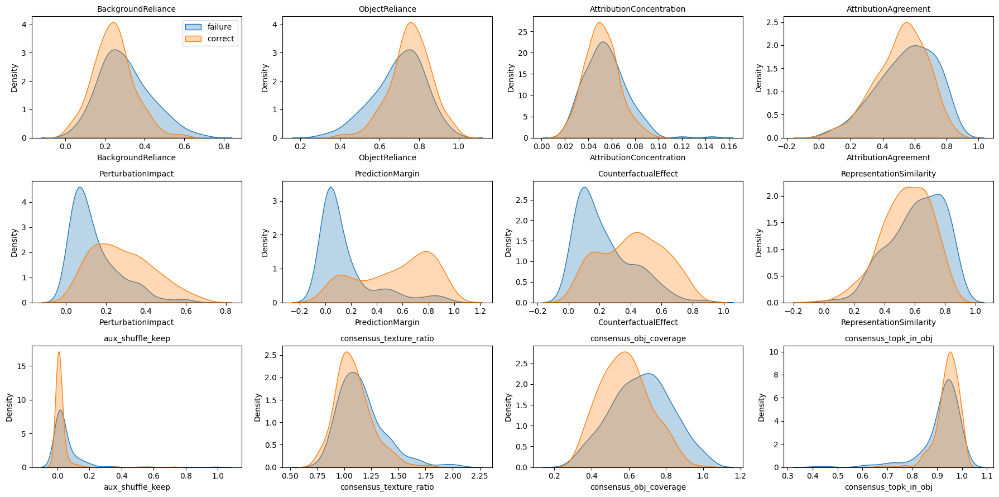

,mean,std,min,25%,50%,75%,max
BackgroundReliance,0.301,0.130,0.012,0.219,0.288,0.381,0.708
ObjectReliance,0.699,0.130,0.292,0.619,0.712,0.781,0.988
AttributionConcentration,0.055,0.018,0.019,0.043,0.053,0.065,0.146
AttributionAgreement,0.548,0.180,0.054,0.429,0.573,0.692,0.849
PerturbationImpact,0.143,0.121,0.007,0.055,0.101,0.200,0.622
PredictionMargin,0.156,0.220,0.000,0.020,0.055,0.196,0.936
CounterfactualEffect,0.233,0.182,0.019,0.087,0.173,0.332,0.876
RepresentationSimilarity,0.612,0.178,0.025,0.487,0.629,0.757,0.874
aux_shuffle_keep,0.051,0.100,0.001,0.007,0.016,0.050,0.986
consensus_texture_ratio,1.160,0.218,0.740,1.000,1.126,1.252,2.055


In [19]:
cols = ["BackgroundReliance", "ObjectReliance", "AttributionConcentration", "AttributionAgreement", "PerturbationImpact",
        "PredictionMargin", "CounterfactualEffect", "RepresentationSimilarity", "aux_shuffle_keep", "consensus_texture_ratio", "consensus_obj_coverage", "consensus_topk_in_obj"]
fig, axs = plt.subplots(3, 4, figsize=(18, 9))
for ax, c in zip(axs.ravel(), cols):
    sns.kdeplot(df_f[c], ax=ax, label="failure", fill=True, alpha=.3, warn_singular=False)
    sns.kdeplot(df_c[c], ax=ax, label="correct", fill=True, alpha=.3, warn_singular=False)
    ax.set_title(c, fontsize=10)
axs[0, 0].legend(); plt.tight_layout(); plt.show()
df_f[cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(3)

*If a mode is empty or swallows everything, adjust `TH` in the cell above and re-run from there (`label_all()` is instant).*

## 10. Stored diagnosis (step 9)
Each record has the fields requested in the algorithm: `image_id, true_class, predicted_class, confidence, attribution_maps (key into maps_store / attribution_maps.npz), important_regions, perturbation_scores, counterfactual_results, failure_indicators, failure_mode`.

In [20]:
def save_all():
    with open(f"{CFG.out_dir}/diagnosis_records.pkl", "wb") as f: pickle.dump(records, f)
    df_diag.to_csv(f"{CFG.out_dir}/diagnosis_table.csv", index=False)
    slim = [{k: v for k, v in r.items() if k not in ("map_indicators",)} for r in records]
    with open(f"{CFG.out_dir}/diagnosis_records.json", "w") as f: json.dump(slim, f, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    np.savez_compressed(f"{CFG.out_dir}/attribution_maps.npz", **maps_store)
    print("saved to", CFG.out_dir)
save_all()
r0 = next(r for r in records if r["group"] == "failure")
print(json.dumps({k: r0[k] for k in ["image_id", "true_class", "predicted_class", "confidence", "failure_indicators", "failure_mode"]}, indent=1, default=float))

saved to /content/drive/MyDrive/vit_diagnosis_outputs
{
 "image_id": "03887",
 "true_class": "Audi S6 Sedan 2011",
 "predicted_class": "BMW ActiveHybrid 5 Sedan 2012",
 "confidence": 0.17263206839561462,
 "failure_indicators": {
  "BackgroundReliance": 0.307989239692688,
  "ObjectReliance": 0.692010760307312,
  "AttributionConcentration": 0.07475346123816962,
  "AttributionAgreement": 0.7310622179367648,
  "PerturbationImpact": 0.12002983689308167,
  "PredictionMargin": 0.0880035012960434,
  "CounterfactualEffect": 0.16418024897575378,
  "RepresentationSimilarity": 0.5104024410247803
 },
 "failure_mode": "OTHER_AMBIGUOUS"
}


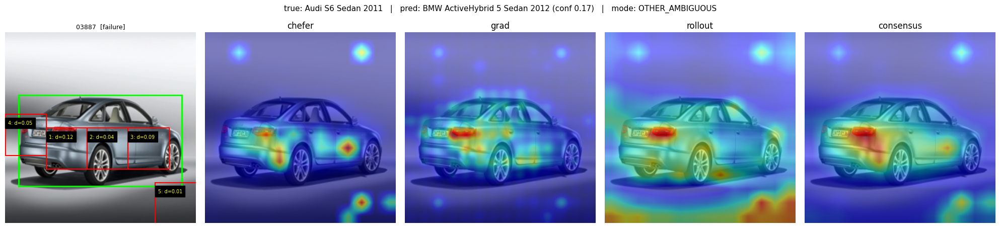

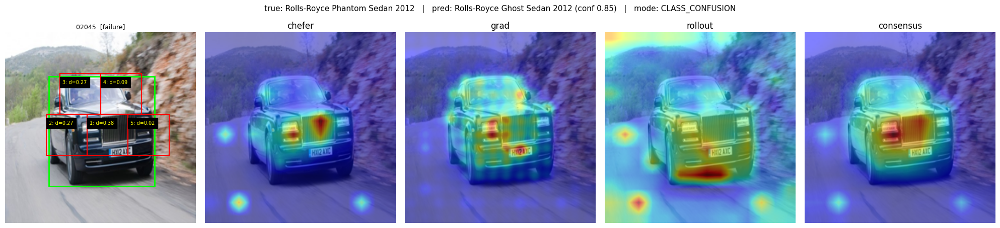

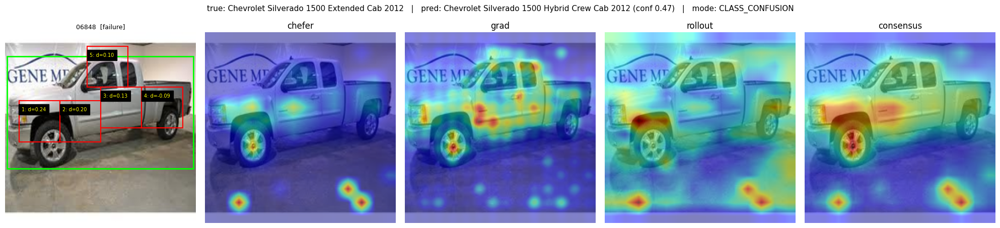

In [21]:
# ---- visualisation of one diagnosed case ----
def plot_case(rec, save_path=None):
    x, y, b = get_item(ds_test, rec["idx"])
    img = denorm(x).permute(1, 2, 0).numpy(); mp = maps_store[rec["image_id"]].astype(np.float32)
    fig, axs = plt.subplots(1, 5, figsize=(20, 4.4))
    axs[0].imshow(img)
    axs[0].add_patch(mpatches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="lime", lw=2))
    for k, r in enumerate(rec["important_regions"]):
        axs[0].add_patch(mpatches.Rectangle((r["c0"]*P, r["r0"]*P), r["size"]*P, r["size"]*P, fill=False, ec="red", lw=1.5))
        axs[0].text(r["c0"]*P+3, r["r0"]*P+12, f"{k+1}: d={r['delta']:.2f}", color="yellow", fontsize=7, backgroundcolor="k")
    for ax, name, m in zip(axs[1:], ALL_MAPS, mp):
        ax.imshow(img); ax.imshow(m, cmap="jet", alpha=0.5); ax.set_title(name)
    axs[0].set_title(f"{rec['image_id']}  [{rec['group']}]", fontsize=9)
    fig.suptitle(f"true: {rec['true_class']}   |   pred: {rec['predicted_class']} (conf {rec['confidence']:.2f})   |   mode: {rec['failure_mode']}", fontsize=11, y=1.02)
    for ax in axs: ax.axis("off")
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=90, bbox_inches="tight"); plt.close(fig)
    else: plt.show()

for r in [r for r in records if r["group"] == "failure"][:3]:
    plot_case(r)

## 11. Aggregation and comparisons (steps 10 and 11)

### 11.1 Aggregate over all failures: mode frequencies and mode-wise indicator profile

,count,share_%
failure_mode,,
BACKGROUND_RELIANCE,0,0.0
LOCALIZATION_FAILURE,21,9.5
TEXTURE_BIAS,0,0.0
CLASS_CONFUSION,128,57.9
PARTIAL_OBJECT_FAILURE,9,4.1
OTHER_AMBIGUOUS,63,28.5


,confidence,BackgroundReliance,ObjectReliance,AttributionConcentration,AttributionAgreement,PerturbationImpact,PredictionMargin,CounterfactualEffect,RepresentationSimilarity
failure_mode,,,,,,,,,
CLASS_CONFUSION,0.324,0.267,0.733,0.055,0.541,0.182,0.218,0.287,0.729
LOCALIZATION_FAILURE,0.126,0.560,0.440,0.061,0.519,0.090,0.067,0.141,0.505
OTHER_AMBIGUOUS,0.149,0.301,0.699,0.054,0.571,0.093,0.079,0.163,0.440
PARTIAL_OBJECT_FAILURE,0.120,0.192,0.808,0.047,0.547,0.062,0.037,0.156,0.419


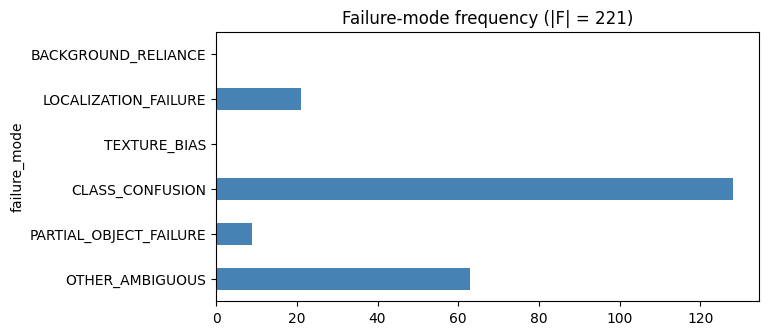

In [22]:
freq = df_f.failure_mode.value_counts().reindex(FAILURE_MODES, fill_value=0)
freq_tbl = pd.DataFrame({"count": freq, "share_%": (100 * freq / freq.sum()).round(1)})
display(freq_tbl)
profile = df_f.groupby("failure_mode")[["confidence", "BackgroundReliance", "ObjectReliance", "AttributionConcentration", "AttributionAgreement",
                                          "PerturbationImpact", "PredictionMargin", "CounterfactualEffect", "RepresentationSimilarity"]].mean().round(3)
display(profile)
freq.plot.barh(figsize=(7, 3.5), color="steelblue"); plt.title("Failure-mode frequency (|F| = %d)" % len(df_f)); plt.gca().invert_yaxis(); plt.show()

### 11.2 Correct vs incorrect predictions
The same rules are applied to correct predictions to see whether the "failure signatures" are really specific to errors.

,failure_mean,correct_mean,diff,mannwhitney_p
indicator,,,,
BackgroundReliance,0.3014,0.2431,0.0583,0.0000
ObjectReliance,0.6986,0.7569,-0.0583,0.0000
AttributionConcentration,0.0549,0.0513,0.0036,0.0433
AttributionAgreement,0.5479,0.5145,0.0334,0.0137
PerturbationImpact,0.1432,0.2832,-0.1400,0.0000
PredictionMargin,0.1564,0.5428,-0.3864,0.0000
CounterfactualEffect,0.2326,0.4116,-0.1790,0.0000
aux_shuffle_keep,0.0513,0.0203,0.0309,0.0000
consensus_texture_ratio,1.1600,1.0878,0.0722,0.0002


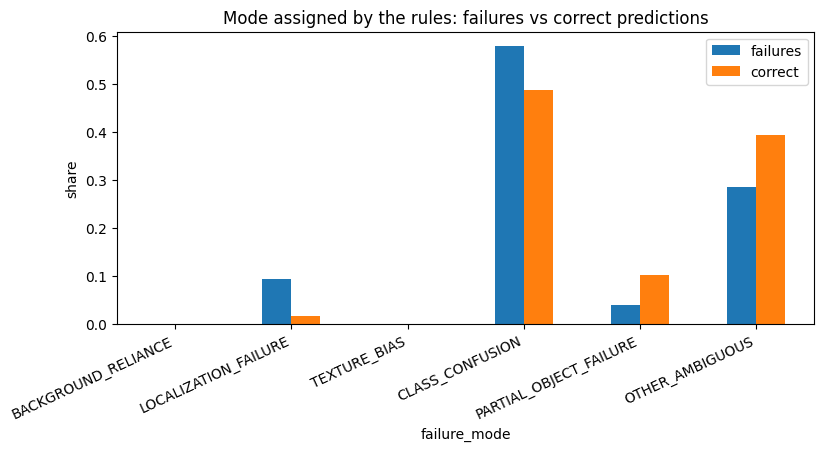

In [23]:
ind_cols = ["BackgroundReliance", "ObjectReliance", "AttributionConcentration", "AttributionAgreement", "PerturbationImpact",
            "PredictionMargin", "CounterfactualEffect", "aux_shuffle_keep", "consensus_texture_ratio", "consensus_obj_coverage", "consensus_topk_in_obj"]
rows = []
for c in ind_cols:
    a, b_ = df_f[c].dropna(), df_c[c].dropna()
    p = mannwhitneyu(a, b_).pvalue if len(a) and len(b_) else np.nan
    rows.append(dict(indicator=c, failure_mean=a.mean(), correct_mean=b_.mean(), diff=a.mean() - b_.mean(), mannwhitney_p=p))
cmp_tbl = pd.DataFrame(rows).set_index("indicator").round(4)
display(cmp_tbl)

modes_cmp = pd.concat([df_f.failure_mode.value_counts(normalize=True).rename("failures"),
                       df_c.failure_mode.value_counts(normalize=True).rename("correct")], axis=1).reindex(FAILURE_MODES).fillna(0)
modes_cmp.plot.bar(figsize=(9, 3.8)); plt.ylabel("share"); plt.title("Mode assigned by the rules: failures vs correct predictions"); plt.xticks(rotation=25, ha="right"); plt.show()

### 11.3 Different classes

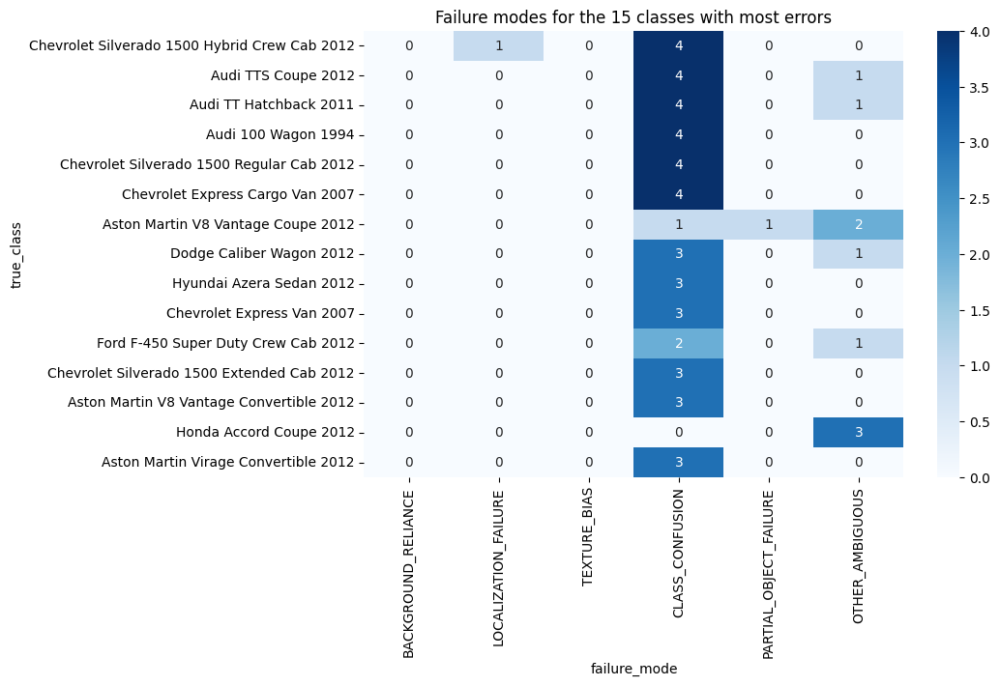

failure_mode,BACKGROUND_RELIANCE,LOCALIZATION_FAILURE,TEXTURE_BIAS,CLASS_CONFUSION,PARTIAL_OBJECT_FAILURE,OTHER_AMBIGUOUS
make,,,,,,
Chevrolet,0,2,0,28,0,6
Audi,0,2,0,24,0,7
BMW,0,3,0,7,2,10
Dodge,0,1,0,12,0,5
Ford,0,1,0,7,1,3
Aston,0,0,0,7,1,3
Bentley,0,0,0,5,2,1
Acura,0,0,0,3,1,2
Hyundai,0,1,0,3,0,2


In [24]:
top_cls = df_f.true_class.value_counts().head(15).index
ct = pd.crosstab(df_f.true_class, df_f.failure_mode).reindex(columns=FAILURE_MODES, fill_value=0).loc[top_cls]
plt.figure(figsize=(9, 6)); sns.heatmap(ct, annot=True, fmt="d", cmap="Blues"); plt.title("Failure modes for the 15 classes with most errors"); plt.show()

df_f = df_f.assign(make=df_f.true_class.map(make_of))
ct_make = pd.crosstab(df_f.make, df_f.failure_mode).reindex(columns=FAILURE_MODES, fill_value=0)
display(ct_make.loc[ct_make.sum(1).sort_values(ascending=False).head(12).index])

### 11.4 Different attribution methods
Per-method diagnosis: each map alone feeds the rules (the perturbation/representation indicators are method independent).

,chefer,grad,rollout,consensus
BACKGROUND_RELIANCE,0.000,0.000,0.023,0.000
LOCALIZATION_FAILURE,0.036,0.027,0.376,0.095
TEXTURE_BIAS,0.000,0.005,0.000,0.000
CLASS_CONFUSION,0.593,0.593,0.385,0.579
PARTIAL_OBJECT_FAILURE,0.045,0.045,0.036,0.041
OTHER_AMBIGUOUS,0.326,0.330,0.181,0.285


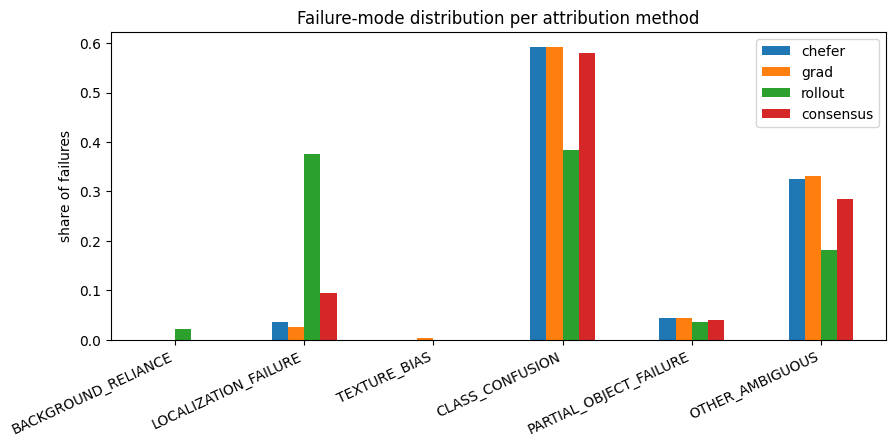

,chefer,grad,rollout,consensus
bg_mass,0.237,0.226,0.441,0.301
concentration,0.110,0.083,0.030,0.055
topk_in_obj,0.896,0.948,0.675,0.915
iou_topk_box,0.393,0.432,0.271,0.409
obj_coverage,0.584,0.695,0.609,0.668
texture_ratio,1.210,1.240,1.029,1.160


In [25]:
mode_cols = [f"mode_{m}" for m in ALL_MAPS]
by_method = pd.concat([df_f[c].value_counts(normalize=True).rename(c.replace("mode_", "")) for c in mode_cols], axis=1).reindex(FAILURE_MODES).fillna(0)
display(by_method.round(3))
by_method.plot.bar(figsize=(10, 4)); plt.ylabel("share of failures"); plt.title("Failure-mode distribution per attribution method"); plt.xticks(rotation=25, ha="right"); plt.show()

stat_cols = ["bg_mass", "concentration", "topk_in_obj", "iou_topk_box", "obj_coverage", "texture_ratio"]
display(pd.DataFrame({m: {s: df_f[f"{m}_{s}"].mean() for s in stat_cols} for m in ALL_MAPS}).round(3))

## 12. Evaluating the diagnosis framework (step 12)

### 12.1 Deletion / insertion curves
Patches are removed (deletion, baseline fill) or revealed on a blurred image (insertion) in order of attribution. Lower deletion-AUC and higher insertion-AUC mean a more faithful map. A random order is the control.

del/ins failures:   0%|          | 0/221 [00:00<?, ?it/s]

del/ins correct:   0%|          | 0/150 [00:00<?, ?it/s]

deletion_AUC         insertion_AUC        
group          correct failure       correct failure
method                                              
chefer          0.0446  0.0236        0.4715  0.2051
consensus       0.0500  0.0269        0.4634  0.1981
grad            0.0550  0.0288        0.4600  0.1936
random          0.2133  0.0937        0.1762  0.0746
rollout         0.1361  0.0623        0.3173  0.1408

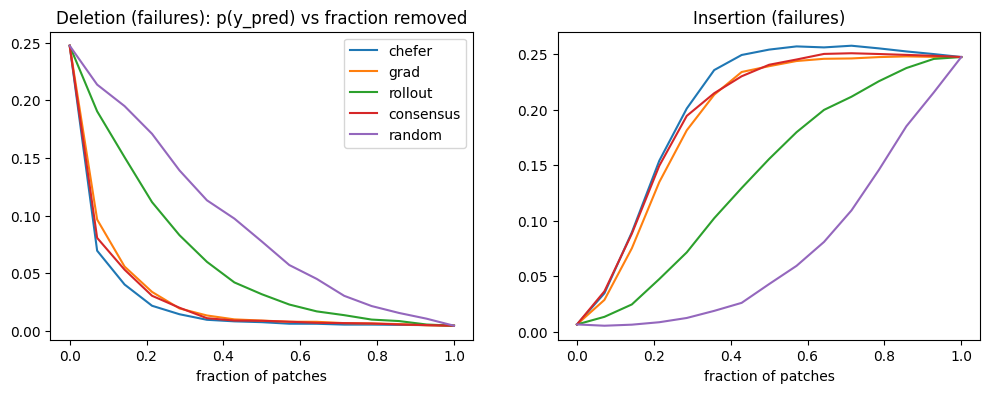

In [26]:
def delins_for(rec, rng):
    x, y, b = get_item(ds_test, rec["idx"]); x = x.to(device)
    mp = maps_store[rec["image_id"]].astype(np.float32)
    a14 = {k: pool14(mp[j]) for j, k in enumerate(ALL_MAPS)}
    a14["random"] = rng.random((G, G))
    fr = np.linspace(0, 1, CFG.delins_steps + 1)
    base_d, base_i = make_baseline(x), make_baseline(x, "blur")
    out = {}
    for k, a in a14.items():
        order = np.argsort(-a.ravel())
        dels, inss = [], []
        for f in fr:
            m = np.zeros(G * G, np.float32); m[order[:int(round(f * G * G))]] = 1; m = up224(m.reshape(G, G))
            dels.append(fill(x, base_d, m)); inss.append(fill(x, base_i, 1 - m))
        pd_ = probe(torch.stack(dels), rec["y_pred"], rec["y_true"])["p_pred"]
        pi_ = probe(torch.stack(inss), rec["y_pred"], rec["y_true"])["p_pred"]
        out[k] = dict(deletion=pd_, insertion=pi_, del_auc=float(trapz(pd_, fr)), ins_auc=float(trapz(pi_, fr)))
    return out

rng_e = np.random.default_rng(0)
eval_f = [r for r in records if r["group"] == "failure"][:CFG.n_eval_failures]
eval_c = [r for r in records if r["group"] == "correct"][:CFG.n_eval_correct]
delins = {"failure": [delins_for(r, rng_e) for r in tqdm(eval_f, desc="del/ins failures")],
          "correct": [delins_for(r, rng_e) for r in tqdm(eval_c, desc="del/ins correct")]}

keys = ALL_MAPS + ["random"]
rows = []
for g, lst in delins.items():
    for k in keys:
        rows.append(dict(group=g, method=k, deletion_AUC=np.mean([d[k]["del_auc"] for d in lst]), insertion_AUC=np.mean([d[k]["ins_auc"] for d in lst])))
delins_tbl = pd.DataFrame(rows).pivot(index="method", columns="group", values=["deletion_AUC", "insertion_AUC"]).round(4)
display(delins_tbl)

fig, axs = plt.subplots(1, 2, figsize=(12, 4)); fr = np.linspace(0, 1, CFG.delins_steps + 1)
for k in keys:
    axs[0].plot(fr, np.mean([d[k]["deletion"] for d in delins["failure"]], 0), label=k)
    axs[1].plot(fr, np.mean([d[k]["insertion"] for d in delins["failure"]], 0), label=k)
axs[0].set_title("Deletion (failures): p(y_pred) vs fraction removed"); axs[1].set_title("Insertion (failures)")
axs[0].legend(); [a.set_xlabel("fraction of patches") for a in axs]; plt.show()

### 12.2 Localisation against the ground-truth bounding box

In [27]:
loc_rows = []
for g, d in [("failure", df_f), ("correct", df_c)]:
    for m in ALL_MAPS:
        loc_rows.append(dict(group=g, method=m, pointing_game=d[f"{m}_pointing_hit"].mean(), mass_in_box=d[f"{m}_obj_mass"].mean(),
                             topk_in_box=d[f"{m}_topk_in_obj"].mean(), IoU_topk_box=d[f"{m}_iou_topk_box"].mean(),
                             box_area_fraction=d["aux_box_area"].mean()))
loc_tbl = pd.DataFrame(loc_rows).set_index(["group", "method"]).round(3)
display(loc_tbl)

pointing_game  mass_in_box  topk_in_box  IoU_topk_box  \
group   method                                                             
failure chefer             0.905        0.763        0.896         0.393   
        grad               0.995        0.774        0.948         0.432   
        rollout            0.629        0.559        0.675         0.271   
        consensus          0.946        0.699        0.915         0.409   
correct chefer             0.933        0.832        0.936         0.341   
        grad               0.980        0.824        0.971         0.362   
        rollout            0.530        0.615        0.671         0.221   
        consensus          0.957        0.757        0.941         0.346   

                   box_area_fraction  
group   method                        
failure chefer                  0.48  
        grad                    0.48  
        rollout                 0.48  
        consensus               0.48  
correct chefer                  0.57  
        grad                    0.57  
        rollout                 0.57  
        consensus               0.57

### 12.3 Perturbation faithfulness
(a) Do the selected regions matter more than random regions of the same size? (b) Across a 7x7 grid of cells, does each method's attribution rank agree with the measured probability drop (Spearman)?

In [28]:
def faith_corr(rec, method):
    a = pool14(maps_store[rec["image_id"]][ALL_MAPS.index(method)].astype(np.float32))
    d = np.asarray(rec["perturbation_scores"]["cell_delta"])
    r = spearmanr(cell_sums(a), d).correlation
    return np.nan if np.isnan(r) else r

rows = []
for g, lst in [("failure", eval_f), ("correct", eval_c)]:
    top_d = np.array([r["perturbation_scores"]["mean_region_delta"] for r in lst])
    rnd_d = np.array([r["perturbation_scores"]["mean_random_delta"] for r in lst])
    row = dict(group=g, top_regions_delta=top_d.mean(), random_regions_delta=rnd_d.mean(),
               frac_images_top_gt_random=(top_d > rnd_d).mean(), wilcoxon_p=np.nan)
    try:
        from scipy.stats import wilcoxon
        row["wilcoxon_p"] = wilcoxon(top_d, rnd_d, alternative="greater").pvalue
    except Exception: pass
    for m in ALL_MAPS: row[f"cell_spearman_{m}"] = np.nanmean([faith_corr(r, m) for r in lst])
    rows.append(row)
faith_tbl = pd.DataFrame(rows).set_index("group").round(4)
display(faith_tbl.T)

group,failure,correct
top_regions_delta,0.0463,0.1057
random_regions_delta,0.0152,0.0463
frac_images_top_gt_random,0.7964,0.8533
wilcoxon_p,0.0000,0.0000
cell_spearman_chefer,0.2586,0.3631
cell_spearman_grad,0.2230,0.3241
cell_spearman_rollout,0.1161,0.1459
cell_spearman_consensus,0.2417,0.3398


### 12.4 Consistency across attribution methods
Cohen's kappa between the failure modes obtained from each map, plus agreement of the maps themselves.

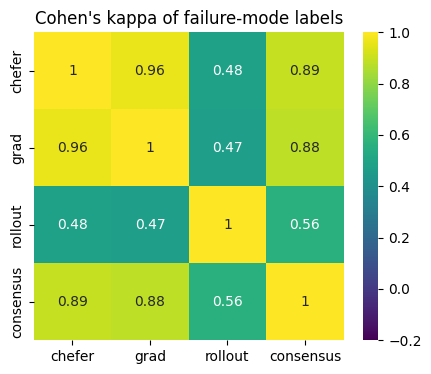

all three single-method diagnoses agree on 62.4% of failures; agree with consensus: chefer 94%, grad 93%, rollout 70%


,spearman,top20%_IoU
chefer-grad,0.787,0.585
chefer-rollout,0.465,0.331
grad-rollout,0.393,0.271


AttributionAgreement  failures: 0.548  correct: 0.515


In [29]:
names = ALL_MAPS
kap = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b_ in names:
        kap.loc[a, b_] = cohen_kappa_score(df_f[f"mode_{a}"], df_f[f"mode_{b_}"]) if a != b_ else 1.0
plt.figure(figsize=(5, 4)); sns.heatmap(kap.astype(float), annot=True, vmin=-0.2, vmax=1, cmap="viridis"); plt.title("Cohen's kappa of failure-mode labels"); plt.show()
all3 = (df_f[["mode_chefer", "mode_grad", "mode_rollout"]].nunique(axis=1) == 1).mean()
print(f"all three single-method diagnoses agree on {100*all3:.1f}% of failures; agree with consensus: " +
      ", ".join(f"{m} {100*(df_f[f'mode_{m}']==df_f.failure_mode).mean():.0f}%" for m in METHODS))

pair_sp = pd.DataFrame([r["agreement"]["spearman_pairs"] for r in records if r["group"] == "failure"]).mean()
pair_iou = pd.DataFrame([r["agreement"]["iou_pairs"] for r in records if r["group"] == "failure"]).mean()
display(pd.DataFrame({"spearman": pair_sp, f"top{int(CFG.topk_frac*100)}%_IoU": pair_iou}).round(3))

# is high agreement associated with the failure/correct group?
print("AttributionAgreement  failures: %.3f  correct: %.3f" % (df_f.AttributionAgreement.mean(), df_c.AttributionAgreement.mean()))

### 12.5 Human validation of the failure labels
1. Run the next cell: it writes a stratified sample (`CFG.human_per_mode` per mode) as PNG panels + a CSV.
2. Open the CSV (on Drive), look at each PNG, and fill in the `human_mode` column with one of the mode names.
3. Run the cell after it to get accuracy, Cohen's kappa and the confusion matrix between the automatic and human labels.

In [30]:
hdir = f"{CFG.out_dir}/human_validation"; os.makedirs(hdir, exist_ok=True)
sample = []
for m in FAILURE_MODES:
    pool = [r for r in records if r["group"] == "failure" and r["failure_mode"] == m]
    pick = np.random.RandomState(1).permutation(len(pool))[:CFG.human_per_mode]
    sample += [pool[j] for j in pick]
for r in tqdm(sample, desc="rendering"):
    plot_case(r, save_path=f"{hdir}/{r['image_id']}.png")
hv = pd.DataFrame([dict(image_id=r["image_id"], true_class=r["true_class"], predicted_class=r["predicted_class"],
                        auto_mode=r["failure_mode"], human_mode="") for r in sample]).sample(frac=1, random_state=0)   # shuffled
hv.to_csv(f"{hdir}/human_labels_TO_FILL.csv", index=False)
print(len(hv), "samples written to", hdir, "\nValid labels:", FAILURE_MODES)

rendering:   0%|          | 0/39 [00:00<?, ?it/s]

39 samples written to /content/drive/MyDrive/vit_diagnosis_outputs/human_validation 
Valid labels: ['BACKGROUND_RELIANCE', 'LOCALIZATION_FAILURE', 'TEXTURE_BIAS', 'CLASS_CONFUSION', 'PARTIAL_OBJECT_FAILURE', 'OTHER_AMBIGUOUS']


In [31]:
# ---- run AFTER filling human_mode in the CSV (use the same file name) ----
hv_f = pd.read_csv(f"{hdir}/human_labels_TO_FILL.csv").dropna(subset=["human_mode"])
hv_f = hv_f[hv_f.human_mode.isin(FAILURE_MODES)]
if len(hv_f) == 0:
    print("No human labels filled in yet.")
else:
    print(f"n = {len(hv_f)} | accuracy = {accuracy_score(hv_f.human_mode, hv_f.auto_mode):.3f} | kappa = {cohen_kappa_score(hv_f.human_mode, hv_f.auto_mode):.3f}")
    cm = confusion_matrix(hv_f.human_mode, hv_f.auto_mode, labels=FAILURE_MODES)
    plt.figure(figsize=(7, 5)); sns.heatmap(pd.DataFrame(cm, index=FAILURE_MODES, columns=FAILURE_MODES), annot=True, fmt="d", cmap="Blues")
    plt.ylabel("human"); plt.xlabel("automatic"); plt.show()

No human labels filled in yet.


## 13. Report (step 13)

### 13.1 Frequency of each failure mode

In [32]:
display(freq_tbl)

,count,share_%
failure_mode,,
BACKGROUND_RELIANCE,0,0.0
LOCALIZATION_FAILURE,21,9.5
TEXTURE_BIAS,0,0.0
CLASS_CONFUSION,128,57.9
PARTIAL_OBJECT_FAILURE,9,4.1
OTHER_AMBIGUOUS,63,28.5


### 13.2 Representative failure cases
For each mode: the three most confidently wrong examples (strongest evidence that the mode is a real model weakness rather than noise).

============================== LOCALIZATION_FAILURE (21 cases) ==============================


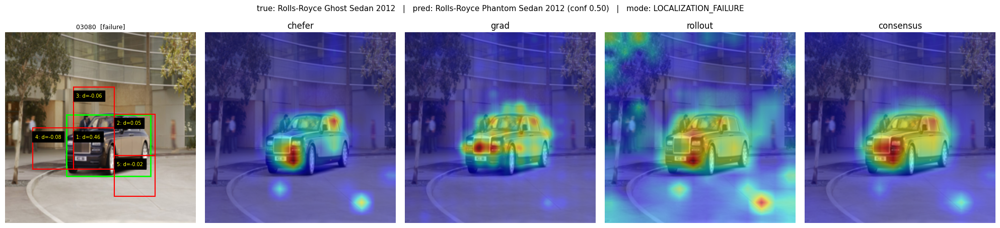

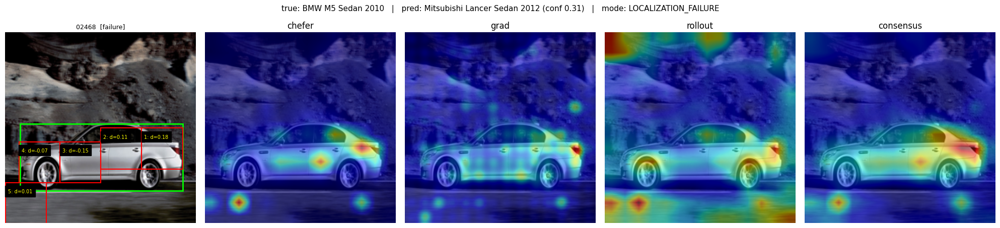

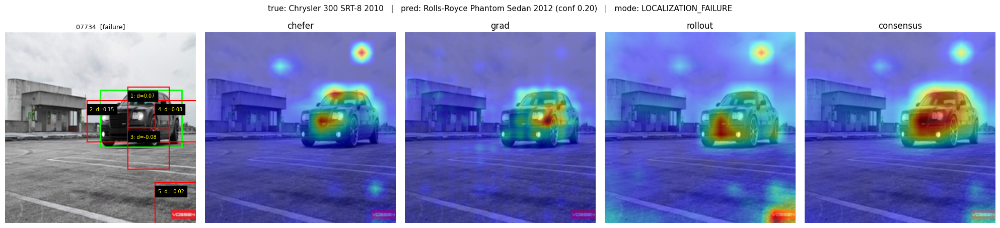

============================== CLASS_CONFUSION (128 cases) ==============================


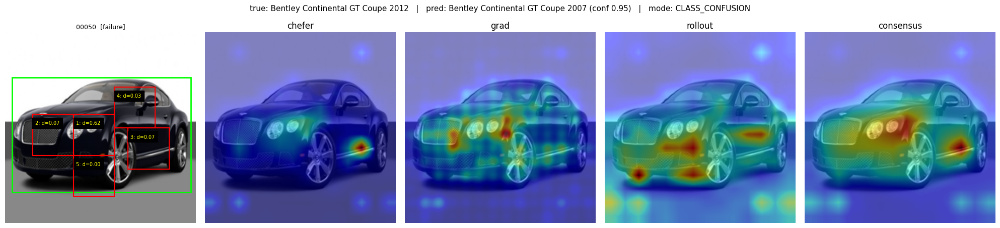

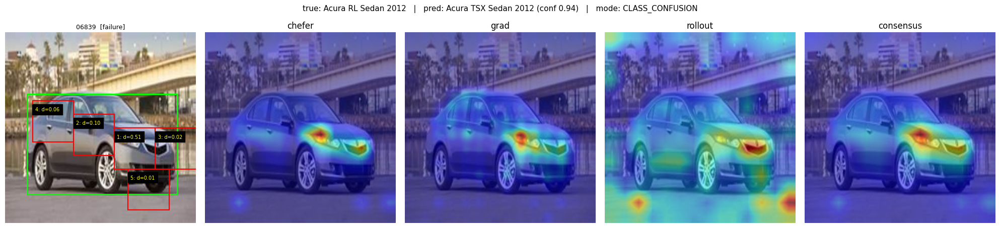

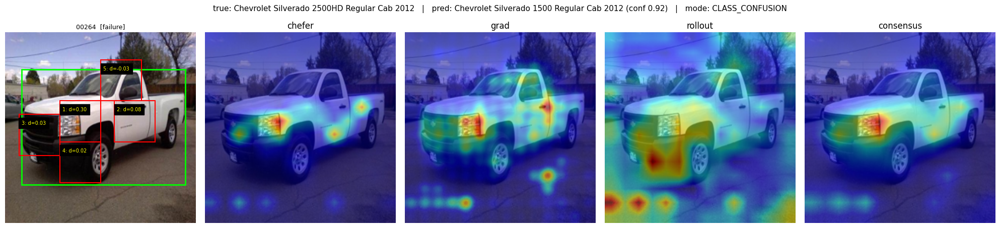

============================== PARTIAL_OBJECT_FAILURE (9 cases) ==============================


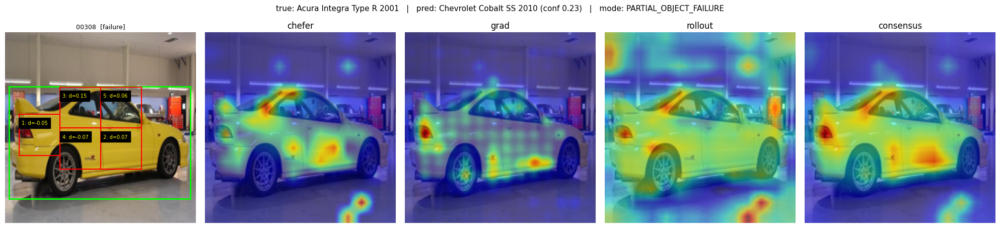

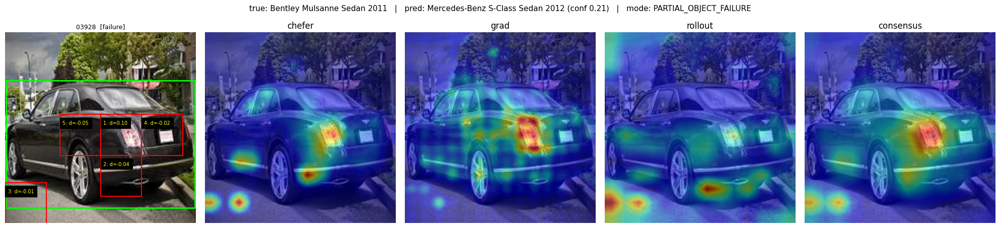

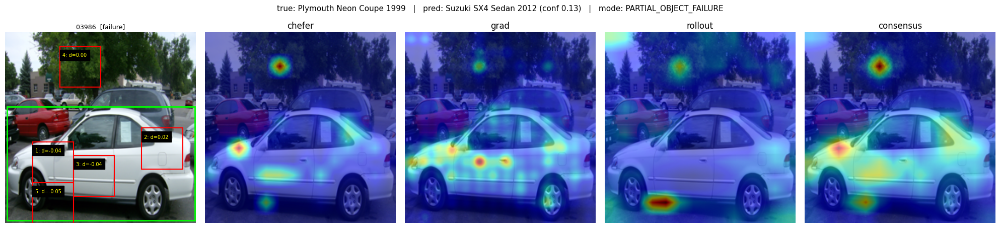

============================== OTHER_AMBIGUOUS (63 cases) ==============================


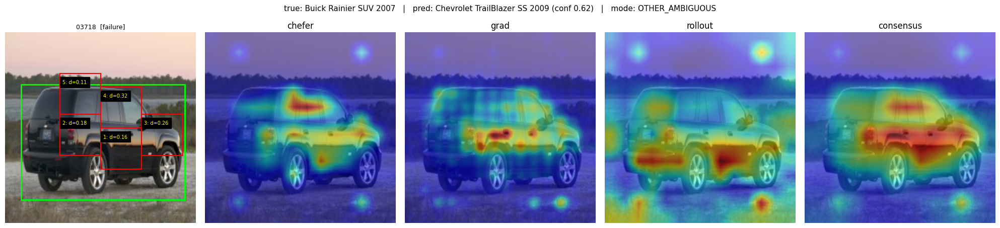

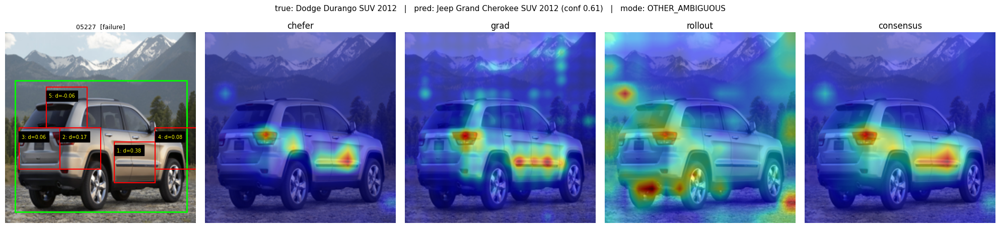

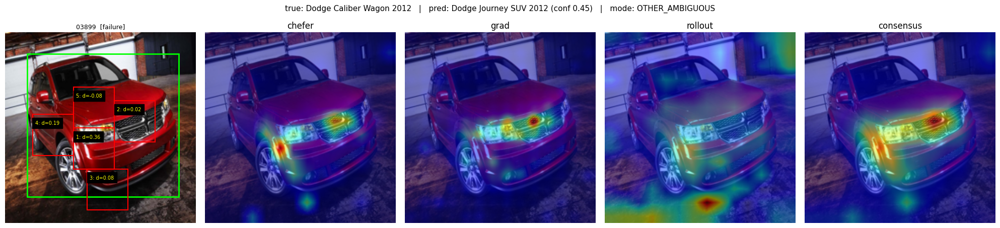

In [33]:
for m in FAILURE_MODES:
    cand = sorted([r for r in records if r["group"] == "failure" and r["failure_mode"] == m], key=lambda r: -r["confidence"])[:3]
    if not cand: continue
    print("=" * 30, m, f"({len([r for r in records if r['group']=='failure' and r['failure_mode']==m])} cases)", "=" * 30)
    for r in cand: plot_case(r)

### 13.3 Attribution / perturbation / counterfactual statistics

In [34]:
cf_cols = {"remove": "cf_remove", "swap with true-class region": "cf_swap"}
rows = []
for name, pre in cf_cols.items():
    d = df_f
    rows.append(dict(counterfactual=name,
                     reduces_conf_pred=d[f"{pre}_reduces_conf_pred"].mean(), increases_conf_true=d[f"{pre}_increases_conf_true"].mean(),
                     changes_class=d[f"{pre}_changes_class"].mean(), flips_to_true=d[f"{pre}_flips_to_true"].mean(),
                     mean_delta_pred=d[f"{pre}_delta_pred"].mean(), mean_delta_true=d[f"{pre}_delta_true"].mean()))
display(pd.DataFrame(rows).set_index("counterfactual").round(3))

pert_tbl = df_f.groupby("failure_mode")[["pert_max_region_delta", "pert_mean_region_delta", "pert_mean_random_delta",
                                          "pert_obj_removed_delta", "pert_bg_removed_delta", "pert_shuffle_keep"]].mean().round(3)
display(pert_tbl)

,reduces_conf_pred,increases_conf_true,changes_class,flips_to_true,mean_delta_pred,mean_delta_true
counterfactual,,,,,,
remove,1.000,0.253,0.819,0.186,0.186,-0.020
swap with true-class region,0.977,0.715,0.882,0.516,0.189,0.067


,pert_max_region_delta,pert_mean_region_delta,pert_mean_random_delta,pert_obj_removed_delta,pert_bg_removed_delta,pert_shuffle_keep
failure_mode,,,,,,
CLASS_CONFUSION,0.182,0.062,0.019,0.317,-0.005,0.030
LOCALIZATION_FAILURE,0.090,0.016,0.012,0.100,0.049,0.133
OTHER_AMBIGUOUS,0.093,0.030,0.010,0.136,0.011,0.066
PARTIAL_OBJECT_FAILURE,0.062,0.016,0.010,0.116,-0.005,0.053


### 13.4 Model weaknesses: hardest classes and most frequent confusions

In [35]:
pc = res.assign(wrong=~res.correct).groupby("class_name").agg(n=("wrong", "size"), errors=("wrong", "sum"), acc=("correct", "mean"), mean_conf=("p_pred", "mean")).sort_values("acc")
display(pc.head(12).round(3))
conf_pairs = F_set.groupby(["y_true", "y_pred"]).size().sort_values(ascending=False).head(12).reset_index(name="count")
conf_pairs["true"] = conf_pairs.y_true.map(class_names.__getitem__); conf_pairs["pred"] = conf_pairs.y_pred.map(class_names.__getitem__)
conf_pairs["proto_cos"] = [proto_cos[a, b_] for a, b_ in zip(conf_pairs.y_true, conf_pairs.y_pred)]
display(conf_pairs[["true", "pred", "count", "proto_cos"]].round(3))

same_make = np.mean([make_of(class_names[a]) == make_of(class_names[b_]) for a, b_ in zip(F_set.y_true, F_set.y_pred)])
same_model = np.mean([base_name(class_names[a]) == base_name(class_names[b_]) for a, b_ in zip(F_set.y_true, F_set.y_pred)])
print(f"{100*same_make:.1f}% of errors stay within the same make, {100*same_model:.1f}% are the same model but a different year")

,n,errors,acc,mean_conf
class_name,,,,
Chevrolet Express Cargo Van 2007,6,4,0.333,0.519
Audi TT Hatchback 2011,8,5,0.375,0.315
Chevrolet Silverado 1500 Hybrid Crew Cab 2012,8,5,0.375,0.467
Audi TTS Coupe 2012,9,5,0.444,0.297
Aston Martin V8 Vantage Coupe 2012,8,4,0.500,0.294
Aston Martin Virage Convertible 2012,6,3,0.500,0.439
Dodge Caliber Wagon 2012,8,4,0.500,0.502
Audi 100 Wagon 1994,9,4,0.556,0.322
Chevrolet Silverado 1500 Regular Cab 2012,9,4,0.556,0.602


,true,pred,count,proto_cos
0,Chevrolet Silverado 1500 Hybrid Crew Cab 2012,Chevrolet Silverado 1500 Extended Cab 2012,4,0.873
1,Audi TT Hatchback 2011,Audi TTS Coupe 2012,3,0.805
2,Audi 100 Wagon 1994,Audi 100 Sedan 1994,3,0.685
3,Bentley Continental GT Coupe 2012,Bentley Continental GT Coupe 2007,3,0.810
4,Audi TTS Coupe 2012,Audi TT Hatchback 2011,3,0.805
5,Rolls-Royce Ghost Sedan 2012,Rolls-Royce Phantom Sedan 2012,3,0.736
6,Dodge Caliber Wagon 2012,Dodge Caliber Wagon 2007,3,0.814
7,Aston Martin Virage Convertible 2012,Aston Martin V8 Vantage Convertible 2012,2,0.815
8,Audi V8 Sedan 1994,Audi 100 Sedan 1994,2,0.799
9,BMW 1 Series Coupe 2012,BMW 1 Series Convertible 2012,2,0.563


49.8% of errors stay within the same make, 5.4% are the same model but a different year


### 13.5 Failure modes vs. prediction confidence

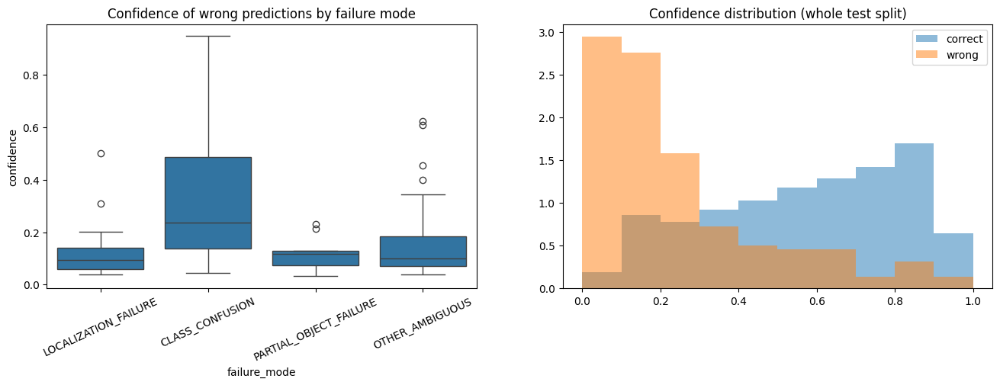

,count,mean,median,std
failure_mode,,,,
CLASS_CONFUSION,128,0.324,0.236,0.242
LOCALIZATION_FAILURE,21,0.126,0.095,0.107
OTHER_AMBIGUOUS,63,0.149,0.100,0.126
PARTIAL_OBJECT_FAILURE,9,0.120,0.118,0.067


4.5% of failures have confidence >= 0.8 (confidently wrong).


confidence,"(0.0, 0.4]","(0.4, 0.6]","(0.6, 0.8]","(0.8, 1.0]"
failure_mode,,,,
CLASS_CONFUSION,0.70,0.14,0.09,0.08
LOCALIZATION_FAILURE,0.95,0.05,0.00,0.00
OTHER_AMBIGUOUS,0.94,0.03,0.03,0.00
PARTIAL_OBJECT_FAILURE,1.00,0.00,0.00,0.00


,"spearman(confidence, indicator) on failures"
BackgroundReliance,-0.270
ObjectReliance,0.270
AttributionConcentration,-0.010
AttributionAgreement,0.006
PerturbationImpact,0.904
CounterfactualEffect,0.819
RepresentationSimilarity,0.599
PredictionMargin,0.880


expected calibration error on the test split: 0.3363


In [36]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
order_modes = [m for m in FAILURE_MODES if (df_f.failure_mode == m).any()]
sns.boxplot(data=df_f, x="failure_mode", y="confidence", order=order_modes, ax=axs[0]); axs[0].tick_params(axis="x", rotation=25)
axs[0].set_title("Confidence of wrong predictions by failure mode")
bins = np.linspace(0, 1, 11)
axs[1].hist(res[res.correct].p_pred, bins=bins, alpha=.5, density=True, label="correct")
axs[1].hist(res[~res.correct].p_pred, bins=bins, alpha=.5, density=True, label="wrong"); axs[1].legend(); axs[1].set_title("Confidence distribution (whole test split)")
plt.show()

display(df_f.groupby("failure_mode").confidence.agg(["count", "mean", "median", "std"]).round(3))
high = df_f.confidence >= 0.8
print(f"{100*high.mean():.1f}% of failures have confidence >= 0.8 (confidently wrong).")
display(pd.crosstab(df_f.failure_mode, pd.cut(df_f.confidence, [0, .4, .6, .8, 1.0]), normalize="index").round(2))

rho = {c: spearmanr(df_f.confidence, df_f[c], nan_policy="omit").correlation for c in
       ["BackgroundReliance", "ObjectReliance", "AttributionConcentration", "AttributionAgreement", "PerturbationImpact", "CounterfactualEffect", "RepresentationSimilarity", "PredictionMargin"]}
display(pd.Series(rho, name="spearman(confidence, indicator) on failures").round(3).to_frame())

ece = lambda conf, ok, n=10: sum(abs(ok[(conf > lo) & (conf <= hi)].mean() - conf[(conf > lo) & (conf <= hi)].mean()) * ((conf > lo) & (conf <= hi)).mean()
                                  for lo, hi in zip(np.linspace(0, 1, n + 1)[:-1], np.linspace(0, 1, n + 1)[1:]) if ((conf > lo) & (conf <= hi)).any())
print(f"expected calibration error on the test split: {ece(res.p_pred.values, res.correct.values.astype(float)):.4f}")

### 13.6 Auto-generated summary

In [37]:
top_mode = freq.idxmax()
print(f"""
SUMMARY
-------
Test accuracy {res.correct.mean():.3f} ({len(F_set)} errors out of {len(res)}). {len(df_f)} errors and {len(df_c)} correct predictions were analysed.
Most frequent failure mode: {top_mode} ({freq[top_mode]} cases, {100*freq[top_mode]/freq.sum():.1f}%).
Mode counts: {freq.to_dict()}
Attribution inside the car box (consensus): failures {df_f.consensus_obj_mass.mean():.2f} vs correct {df_c.consensus_obj_mass.mean():.2f} (box covers {df_f.aux_box_area.mean():.2f} of the image).
Attribution agreement between methods: failures {df_f.AttributionAgreement.mean():.2f} vs correct {df_c.AttributionAgreement.mean():.2f}.
Top regions are {'more' if faith_tbl.loc['failure','top_regions_delta'] > faith_tbl.loc['failure','random_regions_delta'] else 'NOT more'} influential than random regions (delta {faith_tbl.loc['failure','top_regions_delta']:.3f} vs {faith_tbl.loc['failure','random_regions_delta']:.3f}).
{100*same_make:.0f}% of errors stay within the same make; {100*same_model:.0f}% are the same model in a different year.
{100*high.mean():.0f}% of the errors are made with confidence >= 0.8.
""")


SUMMARY
-------
Test accuracy 0.864 (221 errors out of 1629). 221 errors and 300 correct predictions were analysed.
Most frequent failure mode: CLASS_CONFUSION (128 cases, 57.9%).
Mode counts: {'BACKGROUND_RELIANCE': 0, 'LOCALIZATION_FAILURE': 21, 'TEXTURE_BIAS': 0, 'CLASS_CONFUSION': 128, 'PARTIAL_OBJECT_FAILURE': 9, 'OTHER_AMBIGUOUS': 63}
Attribution inside the car box (consensus): failures 0.70 vs correct 0.76 (box covers 0.48 of the image).
Attribution agreement between methods: failures 0.55 vs correct 0.51.
Top regions are more influential than random regions (delta 0.046 vs 0.015).
50% of errors stay within the same make; 5% are the same model in a different year.
5% of the errors are made with confidence >= 0.8.



In [38]:
save_all()
df_diag.to_csv(f"{CFG.out_dir}/diagnosis_table.csv", index=False)
for name, t in [("mode_frequency", freq_tbl), ("indicator_correct_vs_failure", cmp_tbl), ("deletion_insertion", delins_tbl), ("localisation", loc_tbl), ("faithfulness", faith_tbl)]:
    t.to_csv(f"{CFG.out_dir}/report_{name}.csv")
print("all tables saved in", CFG.out_dir)

saved to /content/drive/MyDrive/vit_diagnosis_outputs
all tables saved in /content/drive/MyDrive/vit_diagnosis_outputs


## Notes and limitations
* **Counterfactual swap** pastes the same image location from a reference image of the true class. Poses differ, so a *negative* result is weak evidence; a *positive* result (class flips to `y_true`) is strong evidence that the swapped region carries the discriminative cue.
* **Occlusion** is not annotated in Stanford Cars, so `PARTIAL_OBJECT_FAILURE` uses border truncation of the box and low attribution coverage as proxies.
* **Texture** is measured with local gradient energy and a patch-shuffle test; cars are textured objects by nature (grille, wheels), hence the shuffle condition.
* **Thresholds** in `TH` are heuristics. Inspect the section-9 distributions, and use the human validation (12.5) to calibrate them.
* `CFG.max_failures = 40` gives a ~5 minute dry run of the whole pipeline.